# APRAU 2026/27: Grupo 18
## Projeto de Machine Learning: Dataset Clínico Cardiometabólico

**Membros do grupo:**
- Nome Apelido (n.º 1XXXXXX)
- Nome Apelido (n.º 1XXXXXX)
- Nome Apelido (n.º 1XXXXXX)

**Classes atribuídas:** DI, HT e N (2000 registos)

**Objetivo:** aplicar métodos de regressão e classificação a um dataset clínico multi-doença, analisar o comportamento dos modelos e interpretar criticamente os resultados.

Secções:
1. Setup & Data Loading
2. Exploratory Data Analysis (EDA)
3. Regression: `target_regression`
4. Classification: `target_class`
5. Feature Selection (Ridge, Lasso & Elastic Net)
6. Conclusões Gerais
7. Referências

## 1. Setup & Data Loading

In [1]:
# Detects Colab vs local execution and sets the dataset path
import sys
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    DATASET_PATH = '/content/drive/MyDrive/APRAU/dataset_grupo_18.csv'
else:
    DATASET_PATH = '../dataset_grupo_18.csv'

O notebook deteta automaticamente se está a correr no Colab ou localmente e define o caminho para o dataset.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.linear_model import LinearRegression, LogisticRegression, RidgeClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import (
    train_test_split, cross_val_score, cross_val_predict,
    LeaveOneOut, StratifiedKFold
)
from sklearn.pipeline import make_pipeline
from sklearn.base import clone
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    r2_score, mean_absolute_error, mean_squared_error,
    accuracy_score, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.utils import resample

plt.rcParams['figure.figsize'] = (10, 5)
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)
RANDOM_STATE = 42

Todas as bibliotecas necessárias são importadas num único bloco para facilitar a gestão de dependências. As principais são `pandas`/`numpy` para manipulação de dados, `matplotlib`/`seaborn` para visualização, `statsmodels` para o cálculo do VIF, e `sklearn` para modelos, métricas e pré-processamento.

---
## 2. Exploratory Data Analysis (EDA)

### 2.1 Data Loading

In [3]:
df = pd.read_csv(DATASET_PATH)
print(f'Shape: {df.shape}')
df.head()

Shape: (2000, 35)


,age_level,gender,bmi_level,smoking,age,age_normalized,bmi,HbA1c_level,cholesterol,sleep_hours,triglycerides,physical_activity,family_history,stress_level,low_hdl_cholesterol,high_ldl_cholesterol,blood_pressure,sugar_consumption,crp_level,homocysteine_level,systolic_bp,diastolic_bp,alcohol_intake,salt_intake,heart_rate,hdl,ldl,education_level,employment_status,systolic_index,calcium_baseline,plasma_value,ldl_alternative,target_regression,target_class
0,Middle,Female,Overweight,Never,41,0.448276,26.039307,5.406343,287.000000,8.393934,176.000000,Moderate,No,Medium,No,No,126.000000,Medium,1.656905,5.747705,133.176000,89.793143,15.027543,8.477600,74.022857,64.889143,130.259429,Secondary,Employed,133.176000,9.42,1.111734,128.726611,97.0,N
1,Mature,Female,Normal,Current,47,0.517241,20.800000,6.945000,245.000000,9.800000,60.000000,High,No,Low,No,No,151.462687,Medium,7.000985,12.332504,123.000000,75.000000,8.300000,11.400000,88.000000,67.000000,118.000000,Secondary,Employed,123.000000,9.42,1.162052,129.057613,96.0,DI
2,Senior,Male,Normal,Former,76,0.850574,20.500000,5.362764,218.000000,6.300000,86.000000,Low,No,Low,No,No,149.402373,Medium,7.339123,12.304990,168.000000,79.000000,4.500000,8.700000,84.000000,59.000000,105.000000,Secondary,Unemployed,168.000000,9.42,1.424600,129.050057,169.0,N
3,Young,Female,Overweight,Never,20,0.206897,29.810000,4.800000,225.928571,7.000592,227.250000,High,Yes,High,Yes,Yes,150.785714,Low,7.628842,12.321293,133.642553,89.510638,15.708085,8.439149,73.553191,65.804255,133.378723,Primary,Unemployed,133.642553,9.42,1.063741,164.000000,90.0,N
4,Middle,Male,Overweight,Former,35,0.379310,27.320000,6.000000,225.071183,7.040413,148.762342,Low,No,Medium,No,Yes,147.833988,Low,7.414141,12.534473,134.235362,89.431688,15.107577,8.429047,74.042480,63.850746,130.987371,Secondary,Unemployed,134.235362,9.42,0.952215,130.545353,158.0,N


Foi feito o carregamento o dataset e inspecionamos as primeiras linhas para confirmar que o ficheiro foi lido corretamente: número de linhas/colunas esperado e tipos de dados visíveis.

### 2.2 Dataset Overview

In [4]:
print('=== Data Types ===')
print(df.dtypes)
print('\n=== Missing Values ===')
print(df.isnull().sum())

=== Data Types ===
age_level                object
gender                   object
bmi_level                object
smoking                  object
age                       int64
age_normalized          float64
bmi                     float64
HbA1c_level             float64
cholesterol             float64
sleep_hours             float64
triglycerides           float64
physical_activity        object
family_history           object
stress_level             object
low_hdl_cholesterol      object
high_ldl_cholesterol     object
blood_pressure          float64
sugar_consumption        object
crp_level               float64
homocysteine_level      float64
systolic_bp             float64
diastolic_bp            float64
alcohol_intake          float64
salt_intake             float64
heart_rate              float64
hdl                     float64
ldl                     float64
education_level          object
employment_status        object
systolic_index          float64
calcium_baseline     

Inspecionar os tipos de dados e a contagem de valores em falta é o primeiro diagnóstico de qualquer dataset. Confirma se colunas numéricas foram lidas como `object` e se é necessária imputação antes da modelação. Neste caso, o dataset **não possui valores em falta**.

In [5]:
# Separate feature types
categorical_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()
numerical_cols   = df.select_dtypes(include=[np.number]).columns.tolist()

print('Categorical:', categorical_cols)
print('Numerical:  ', numerical_cols)

Categorical: ['age_level', 'gender', 'bmi_level', 'smoking', 'physical_activity', 'family_history', 'stress_level', 'low_hdl_cholesterol', 'high_ldl_cholesterol', 'sugar_consumption', 'education_level', 'employment_status', 'target_class']
Numerical:   ['age', 'age_normalized', 'bmi', 'HbA1c_level', 'cholesterol', 'sleep_hours', 'triglycerides', 'blood_pressure', 'crp_level', 'homocysteine_level', 'systolic_bp', 'diastolic_bp', 'alcohol_intake', 'salt_intake', 'heart_rate', 'hdl', 'ldl', 'systolic_index', 'calcium_baseline', 'plasma_value', 'ldl_alternative', 'target_regression']


Foi feito a separação das colunas em dois grupos: numéricas e categóricas. A análise exploratória e as visualizações diferem entre os dois tipos: histogramas e correlação de Pearson para numéricas; gráficos de barras e tabelas de frequência para categóricas.

In [6]:
# Class balance
print('=== target_class distribution ===')
print(df['target_class'].value_counts())
df['target_class'].value_counts().plot(kind='bar', title='target_class distribution')
plt.tight_layout()
plt.show()

=== target_class distribution ===
target_class
N     1450
DI     467
HT      83
Name: count, dtype: int64


<Figure size 1000x500 with 1 Axes>

Verificar o equilíbrio de classes é crítico em classificação. Com desequilíbrio severo, um classificador pode atingir alta *accuracy* prevendo sempre a classe maioritária sem aprender nada útil. Isto obriga o uso de `StratifiedKFold` e métricas como F1 macro em vez de accuracy isolada.

### 2.3 Descriptive Statistics

In [7]:
df[numerical_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
age,2000.0,46.778500,22.182120,2.000000,29.000000,47.000000,65.000000,89.000000
age_normalized,2000.0,0.514695,0.254967,0.000000,0.310345,0.517241,0.724137,1.000000
bmi,2000.0,27.097259,6.675740,10.590000,22.430000,27.320000,30.971278,64.270000
HbA1c_level,2000.0,5.712300,1.033372,3.500000,5.245652,5.700000,6.500000,9.000000
cholesterol,2000.0,223.494228,28.249128,150.000000,217.232323,225.000000,229.631579,299.000000
sleep_hours,2000.0,6.930174,1.154802,4.000000,6.770819,6.968389,7.080402,10.000000
triglycerides,2000.0,201.077147,64.646075,50.000000,149.733553,228.500000,251.281250,393.000000
blood_pressure,2000.0,150.123830,4.221680,121.000000,148.680000,149.713320,150.720942,180.000000
crp_level,2000.0,7.502463,0.951538,0.900569,7.312963,7.462859,7.824534,14.156036
homocysteine_level,2000.0,12.443702,0.935000,5.384979,12.287763,12.503725,12.691084,19.950612


Usamos `describe()` apenas sobre as colunas numéricas para evitar misturar métricas inaplicáveis: estatísticas como `mean` e `std` não fazem sentido para variáveis categóricas, e `unique`/`top`/`freq` não se aplicam a variáveis numéricas.

Estatísticas descritivas das features numéricas (média, desvio-padrão, quartis, mínimo e máximo). Procuramos features com desvio-padrão próximo de zero (possível variância constante), outliers onde o máximo está muito afastado do Q3, e médias em zonas de risco clínico.

### 2.4 Univariate Analysis

Histogramas de 30 bins para cada feature numérica revelam a forma da distribuição (normal, assimétrica, bimodal), outliers em caudas longas, features constantes (barra única) e padrões de imputação massiva (pico central dominante). Estas observações fundamentam as decisões de tratamento de dados na secção 2.6.

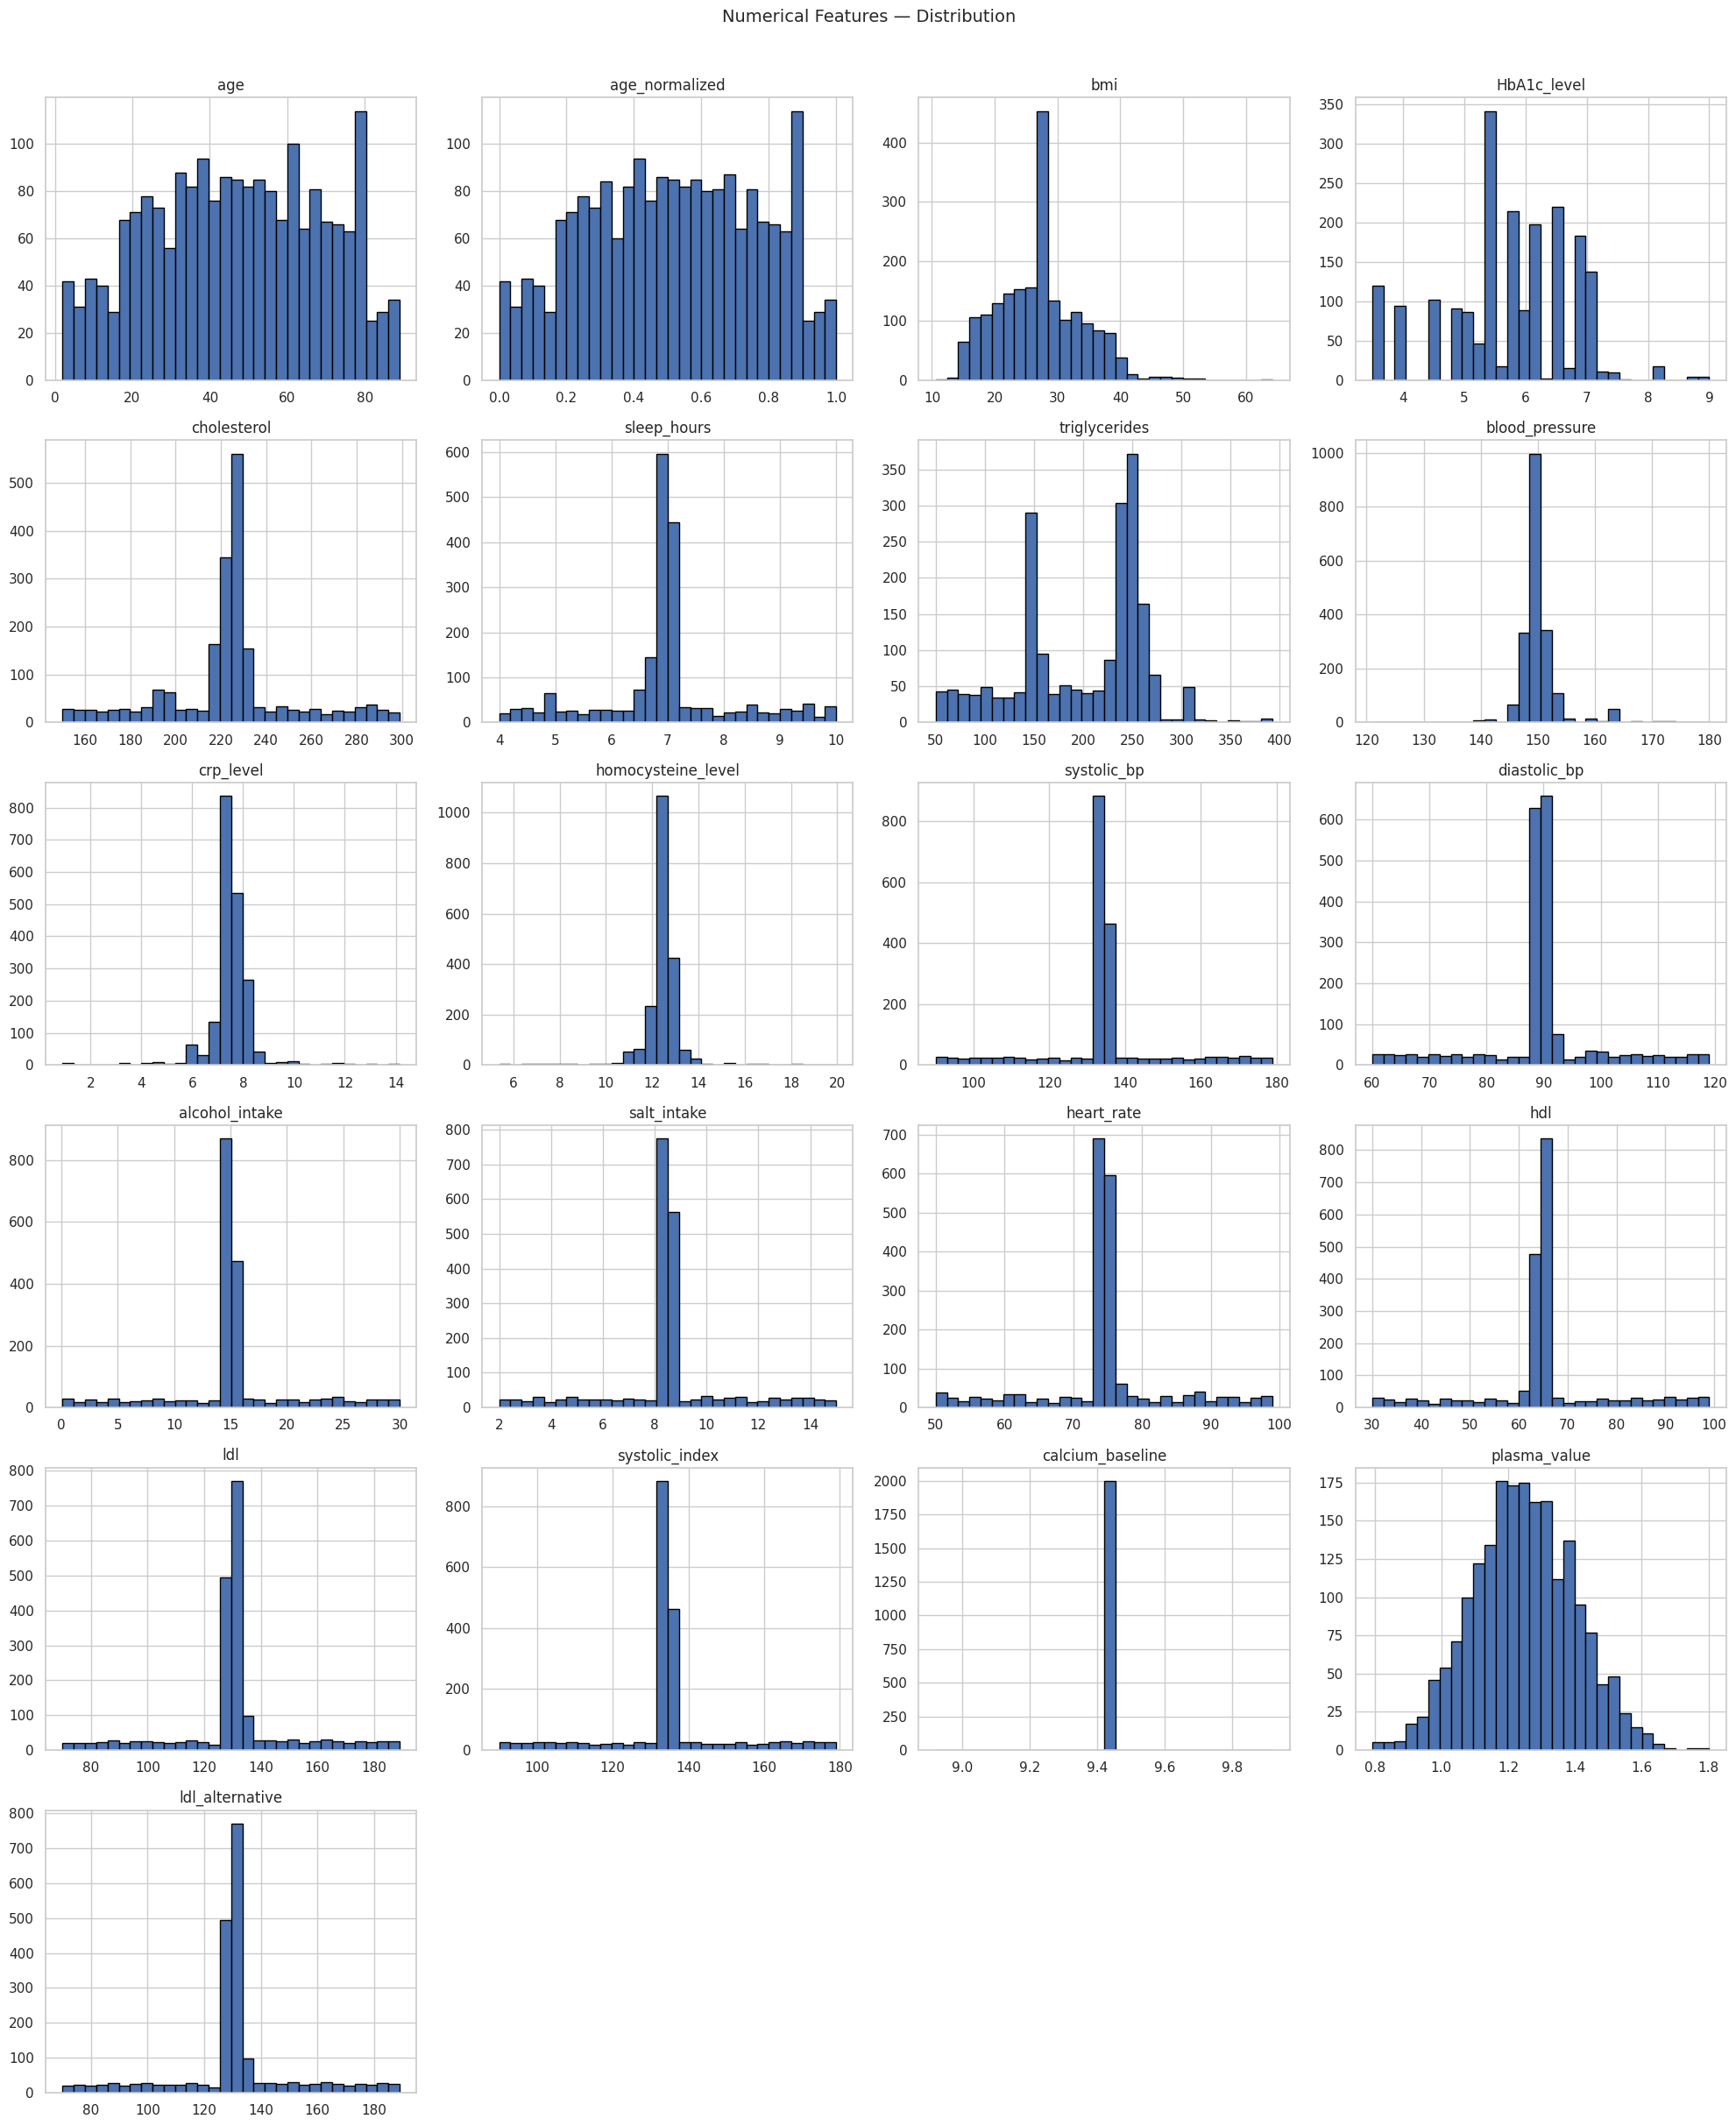

In [8]:
# Histograms for numerical features
num_features = [c for c in numerical_cols if c not in ['target_regression']]
n = len(num_features)
cols = 4
rows = (n + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(20, rows * 4))
axes = axes.flatten()

for i, col in enumerate(num_features):
    axes[i].hist(df[col].dropna(), bins=30, edgecolor='black')
    axes[i].set_title(col)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Numerical Features — Distribution', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

#### Conclusões: Features Numéricas

1. **Vários histogramas revelam padrões de imputação massiva.** As variáveis `cholesterol`, `blood_pressure`, `systolic_bp`, `diastolic_bp`, `salt_intake`, `heart_rate`, `hdl`, `ldl`, `systolic_index` e `ldl_alternative` apresentam todas o mesmo padrão: uma barra central dominante com caudas muito reduzidas. Isto sugere que grande parte das observações tem valores calculados a partir de médias ou regras de imputação, e não medições diretas (em `systolic_bp`, `hdl`, `ldl` e `heart_rate`, mais de metade dos valores está a menos de 0.1 desvios-padrão da mediana). Estas variáveis deverão, por isso, ter baixo poder discriminante real.

2. **Quatro variáveis bimodais sugerem heterogeneidade clínica real na população.** `triglycerides`, `crp_level`, `homocysteine_level` e `alcohol_intake` apresentam dois picos distintos, evidenciando a existência de dois subgrupos populacionais com perfis de risco diferentes. Em `triglycerides`, os picos surgem a ~150 e ~230 mg/dL; em `crp_level` e `homocysteine_level`, um grupo com valores baixos (risco reduzido) e um grupo dominante com valores elevados (risco inflamatório/cardiovascular aumentado). Em `alcohol_intake`, os dois picos refletem dois padrões de consumo opostos. Esta bimodalidade pode ser informativa para a classificação.

3. **`calcium_baseline` tem variância zero e foi removida.** O histograma confirma visualmente o que as estatísticas descritivas já indicavam: uma única barra no valor 9.42 sem qualquer dispersão. Uma variável constante não transmite nenhuma informação ao modelo e foi, por isso, eliminada no passo de tratamento de dados.

4. **Dois pares de variáveis redundantes foram identificados e um elemento de cada par foi removido.** Os histogramas de `age` e `age_normalized` têm exatamente a mesma forma (transformação linear) e os de `systolic_bp` e `systolic_index` são idênticos. A análise de correlação confirmou |r| = 1.00 em ambos os casos. Os histogramas de `ldl` e `ldl_alternative` são também idênticos, mas por outro motivo: `ldl_alternative` contém exatamente os mesmos valores que `ldl` por outra ordem (r ≈ -0.02), como se verifica na secção 2.6.

5. **`plasma_value` é a única feature com distribuição genuinamente normal e contínua.** O seu histograma apresenta uma curva em forma de seno centrada em ~1.2–1.3, sem picos artificiais nem concentrações anómalas. É provável que corresponda a uma medição laboratorial direta sem imputação significativa.

6. **`bmi` apresenta assimetria à direita com cauda longa.** A maioria dos valores concentra-se entre 20 e 35 kg/m², mas a cauda estende-se até ~64 kg/m², indicando casos de obesidade mórbida extrema. Estes outliers não foram removidos por serem clinicamente plausíveis, mas podem influenciar modelos sensíveis à escala.


Analisamos as features categóricas para identificar dominância extrema de uma categoria (que indicaria baixo poder discriminante) e para confirmar o número de classes distintas antes do encoding.

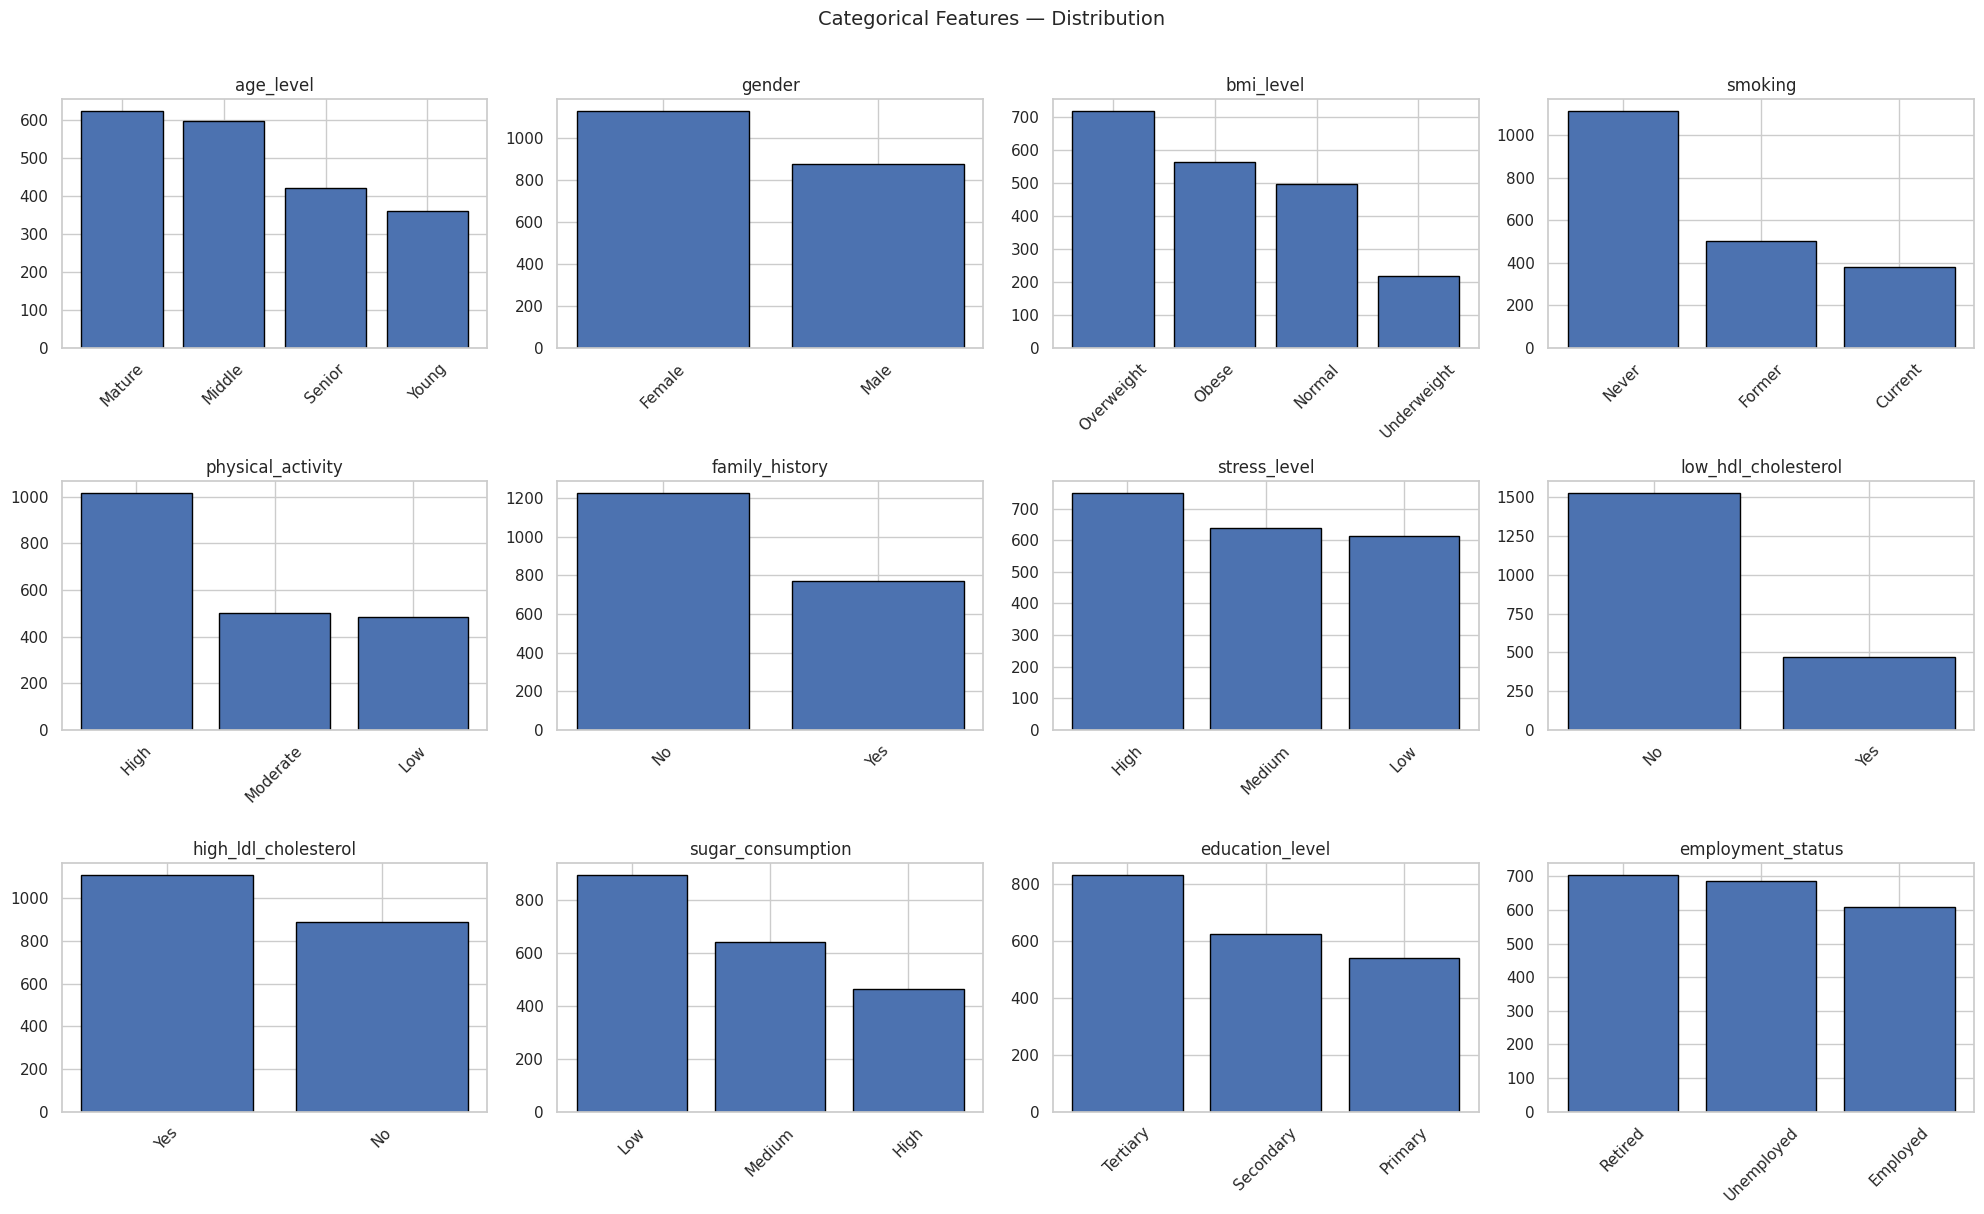

In [9]:
# Bar charts for categorical features
cat_features = [c for c in categorical_cols if c != 'target_class']
n = len(cat_features)
cols = 4
rows = (n + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(20, rows * 4))
axes = axes.flatten()

for i, col in enumerate(cat_features):
    counts = df[col].value_counts()
    axes[i].bar(counts.index, counts.values, edgecolor='black')
    axes[i].set_title(col)
    axes[i].tick_params(axis='x', rotation=45)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Categorical Features — Distribution', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

#### Conclusões: Features Categóricas

1. **Perfil clínico coerente com a população-alvo.** A predominância de `Mature` e `Senior` em `age_level`, combinada com `Overweight` e `Obese` em `bmi_level`, é consistente com um estudo de doenças cardiometabólicas. A exposição ao risco acumula-se com a idade e o excesso de peso é um fator de risco.

2. **Nenhuma categoria com dominância extrema.** Nenhuma feature tem uma classe com dominância extrema. Isto significa que todas as features categóricas têm alguma variabilidade que o modelo pode aprender.

3. **Paradoxo da atividade física.** `physical_activity` tem "High" como categoria mais frequente apesar do perfil de risco elevado da população. Isto pode refletir que a prática de atividade física é declarada (auto-reporte) e não necessariamente eficaz para mitigar outros fatores de risco. Esta feature pode ter baixo poder discriminante para `target_class` apesar da sua prevalência.

4. **`high_ldl_cholesterol` e `family_history` como potenciais preditores.** Ter LDL elevado numa população maioritariamente saudável é clinicamente relevante: LDL elevado é um fator de risco independente. `family_history` é também substancial e difícil de controlar pelo indivíduo, tornando-a um marcador de risco estrutural.

5. **`employment_status`** apresenta uma distribuição praticamente uniforme entre as três categorias. Do ponto de vista de entropia de informação, esta é a feature mais equilibrada do conjunto, mas a sua ligação direta ao desenvolvimento de diabetes ou hipertensão é menos óbvia do que as restantes, cabendo à etapa de Feature Selection determinar se o seu contributo é real.

### 2.5 Bivariate Analysis

A matriz de correlação de Pearson deteta redundâncias. Pares com |r| ≈ 1.0 transportam a mesma informação e introduziriam multicolinearidade perfeita em modelos lineares. É também o ponto de partida para a análise VIF mais formal na secção de tratamento.

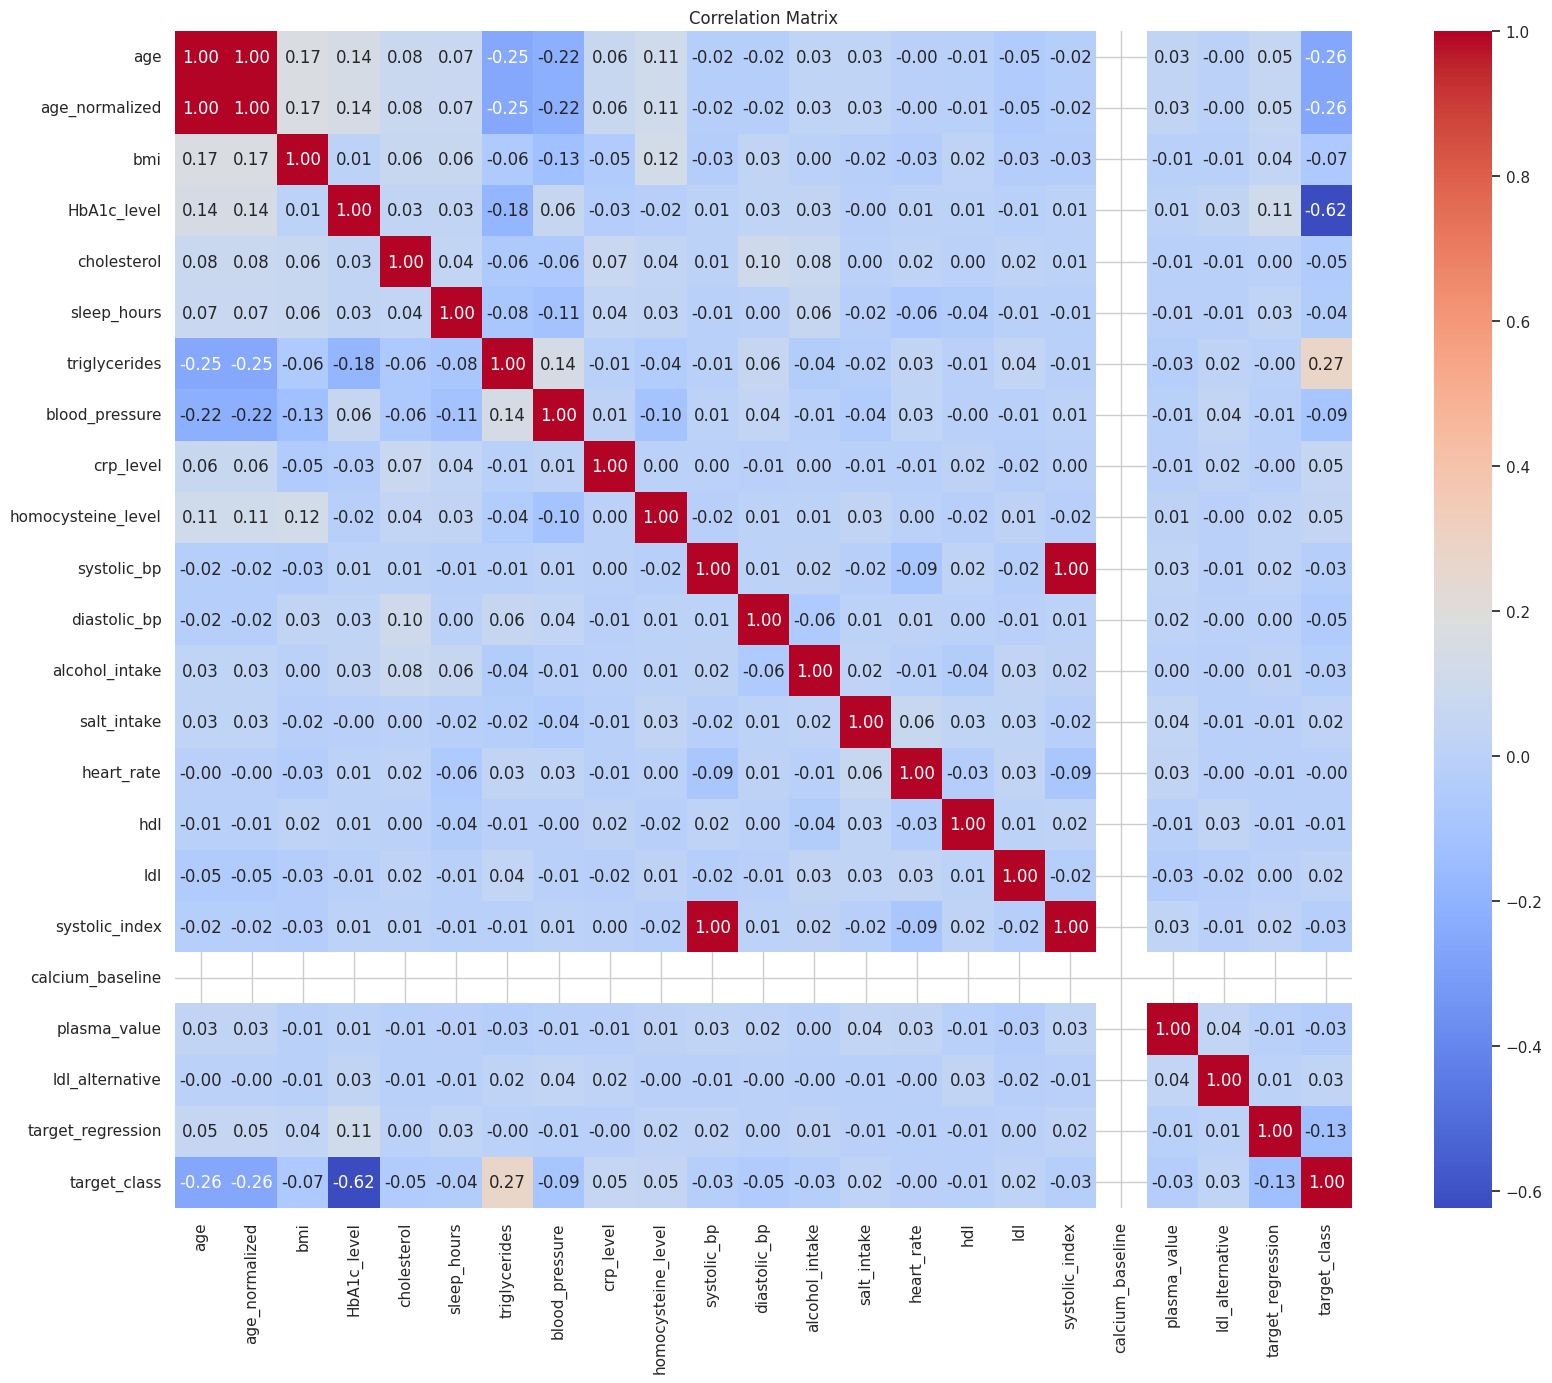

In [10]:
# Correlation heatmap: numerical features + target_class
_tc_map = {v: i for i, v in enumerate(sorted(df["target_class"].unique()))}
corr_df = df[numerical_cols].copy()
corr_df["target_class"] = df["target_class"].map(_tc_map)

corr = corr_df.corr()
plt.figure(figsize=(18, 14))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", square=True)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()


#### Conclusões: Matriz de Correlação

1. **A maioria das correlações é muito fraca.** Quase todos os pares de features apresentam valores de |r| < 0.15, o que confirma que as variáveis numéricas são amplamente independentes entre si. Isto é esperado, dado que muitas delas resultam de imputação, o que atenua artificialmente as correlações.

2. **Dois pares de variáveis perfeitamente correlacionadas foram identificados.** Os blocos vermelho-escuros com r = 1.00 entre `age` e `age_normalized` e entre `systolic_bp` e `systolic_index` confirmam redundância total. Manter ambas as colunas num modelo introduziria multicolinearidade perfeita; um elemento de cada par foi removido no tratamento de dados.

3. **`calcium_baseline` aparece como linha e coluna em branco.** A ausência de qualquer cor reflete variância zero: uma feature constante tem correlação indefinida com qualquer outra variável. Foi removida por não conter informação discriminante.

4. **As correlações mais relevantes entre features envolvem `triglycerides` e `blood_pressure` com `age`.** São as únicas correlações moderadas visíveis: `triglycerides` com `age` (r = -0.25) e `blood_pressure` com `age` (r = -0.22). Ambas são negativas, sugerindo que valores mais baixos destas variáveis estão associados a idades mais avançadas.

5. **`target_class` (codificada como inteiro: DI=0, HT=1, N=2) mostra correlações fracas, mas interpretáveis, com as features numéricas.** As correlações mais expressivas são com `age` e `HbA1c_level`: valores mais elevados destas features associam-se a DI e HT (inteiros menores), resultando em correlações negativas. Nenhuma feature numérica apresenta |r| > 0.15 com esta codificação. No entanto, a codificação é arbitrária (ordem alfabética) e não representa gravidade; a análise por classe (one-hot), apresentada a seguir, revela associações bem mais fortes, nomeadamente `HbA1c_level` com DI (r = 0.64).

A codificação de `target_class` como inteiro (DI=0, HT=1, N=2) segue apenas a ordem alfabética e não representa gravidade. Como a variável é nominal, a correlação de Pearson com esse inteiro depende de uma ordem arbitrária. Para uma análise correta, calculamos a correlação de cada feature numérica com uma variável binária por classe (one-hot: `is_DI`, `is_HT`, `is_N`), que não depende de qualquer ordem.

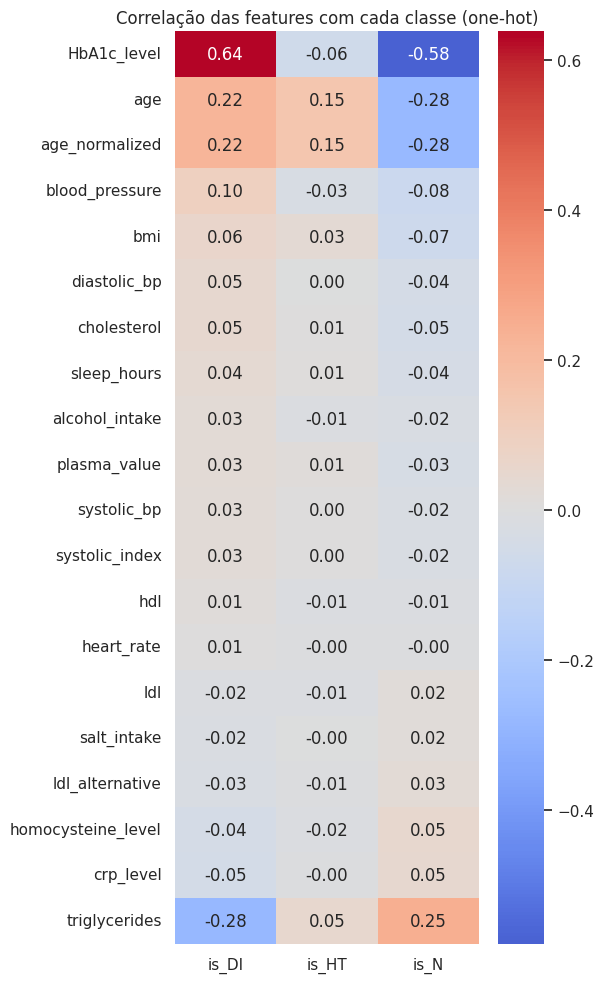

In [11]:
# Correlation of each numerical feature with each class (one-hot), independent of label order
class_dummies = pd.get_dummies(df['target_class'], prefix='is', dtype=int)
corr_by_class = (pd.concat([df[num_features], class_dummies], axis=1)
                 .corr()[class_dummies.columns]
                 .drop(class_dummies.columns)
                 .dropna()                      # calcium_baseline is constant -> undefined correlation
                 .sort_values('is_DI', ascending=False))

plt.figure(figsize=(6, 10))
sns.heatmap(corr_by_class, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlação das features com cada classe (one-hot)')
plt.tight_layout()
plt.show()

#### Conclusões: Correlação por classe

1. **`HbA1c_level` é fortemente associado à classe DI (r = 0.64) e negativamente à classe N (r = -0.58).** É de longe a relação mais forte do dataset, e a matriz anterior não a mostrava: com a codificação DI=0, HT=1, N=2, o efeito de DI e o de N anulavam-se parcialmente. Confirma que a hemoglobina glicada é o principal marcador de diabetes neste dataset.

2. **`age` associa-se às duas classes de doença** (r = 0.22 com DI e 0.15 com HT; -0.28 com N): os doentes são, em média, mais velhos.

3. **`triglycerides` associa-se negativamente a DI (r = -0.28) e positivamente a N (r = 0.25),** o que confirma o padrão contraintuitivo observado nos boxplots.

4. **Nenhuma feature numérica tem correlação relevante com HT** (máx. |r| = 0.15, `age`). Antecipa-se que HT será a classe mais difícil de prever.

5. As restantes features (`cholesterol`, `crp_level`, `hdl`, `ldl`, `heart_rate`, etc.) têm |r| < 0.10 com todas as classes.

Boxplots de cada feature numérica segmentados por `target_class` revelam o poder discriminante visual: classes com medianas e IQR distintos são boas candidatas a preditores. Permitem também identificar se outliers se concentram numa classe específica.

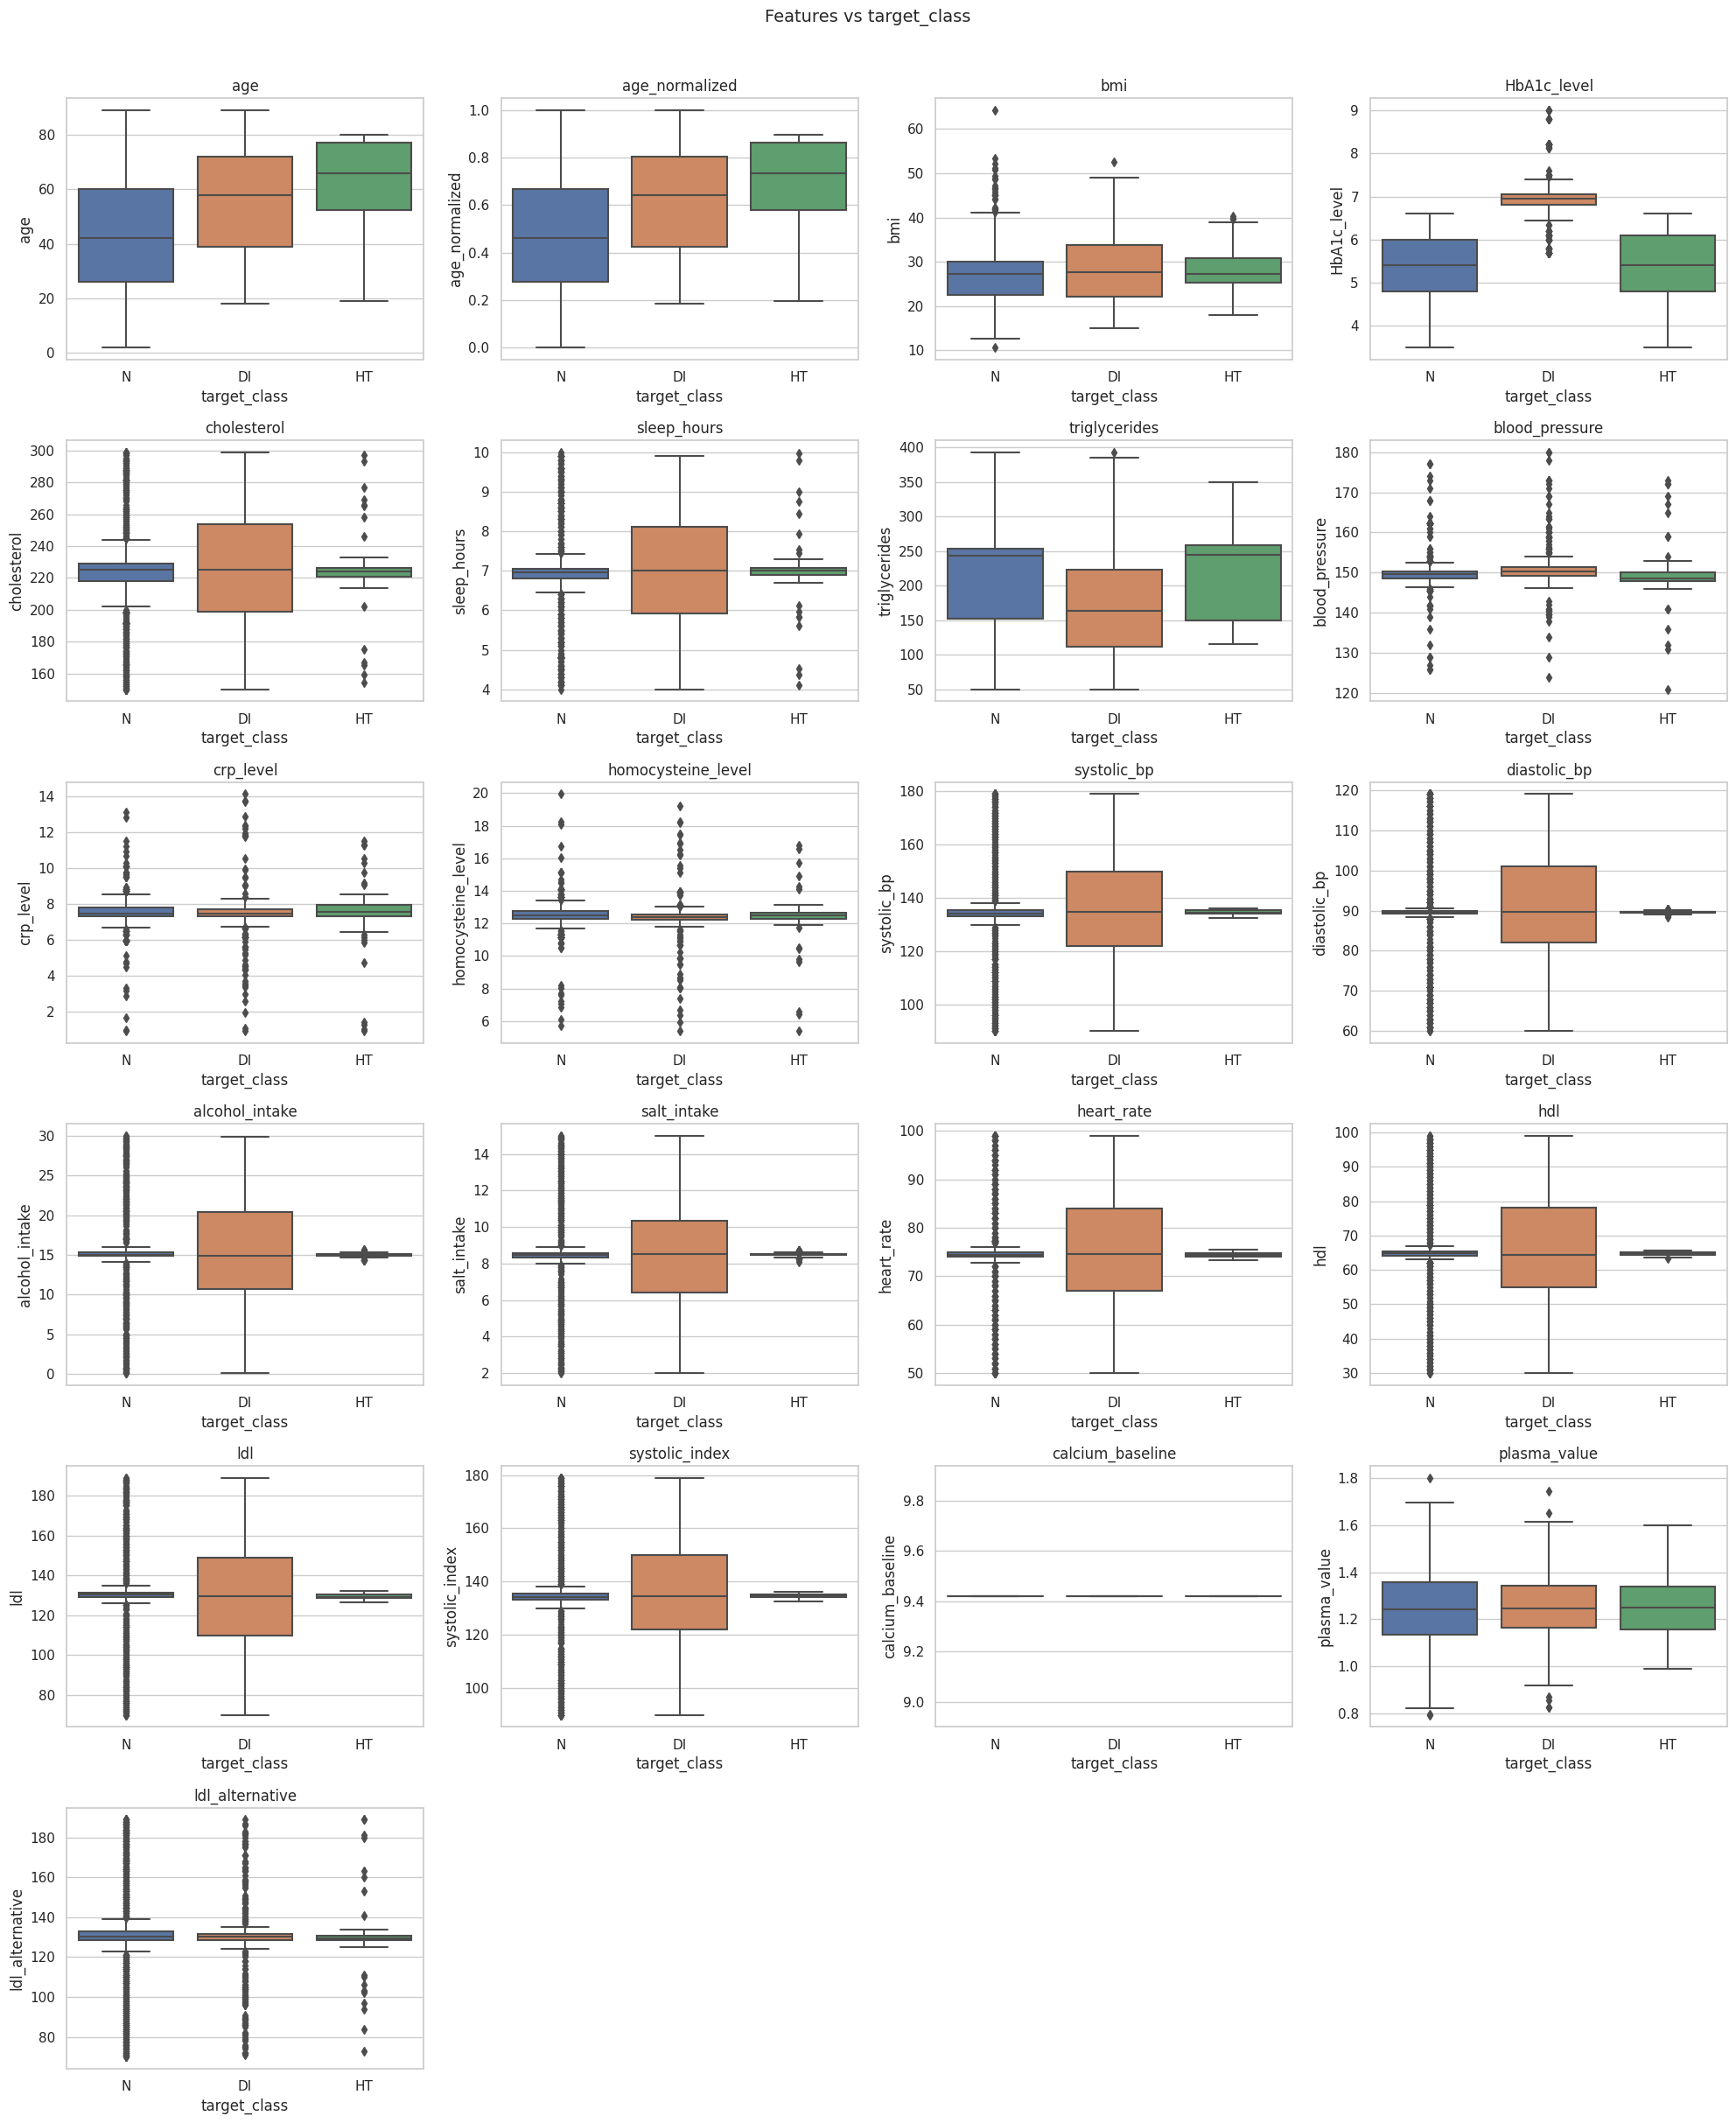

In [12]:
# Boxplots: numerical features vs target_class
n = len(num_features)
cols = 4
rows = (n + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(20, rows * 4))
axes = axes.flatten()

for i, col in enumerate(num_features):
    sns.boxplot(x='target_class', y=col, data=df, ax=axes[i])
    axes[i].set_title(col)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Features vs target_class', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

#### Conclusões: Boxplots Features vs `target_class`

Os boxplots complementam a matriz de correlação ao mostrar a **distribuição por classe** (medianas, IQR e outliers), em vez de um único coeficiente de correlação.

1. **`age` e `HbA1c_level` são os melhores discriminadores visuais.** Em `age`, a mediana aumenta claramente de N para DI e HT, com sobreposição reduzida entre as caixas. Em `HbA1c_level`, a classe DI tem mediana claramente superior face a N e HT, o que é clinicamente esperado: a hemoglobina glicada é o marcador de referência para a diabetes.

2. **`bmi` discrimina DI das restantes classes.** A classe DI apresenta mediana de IMC visivelmente superior a N e HT, consistente com a associação clínica entre obesidade e resistência à insulina. N e HT têm distribuições semelhantes entre si.

3. **A classe DI exibe sistematicamente caixas muito mais largas.** Em `systolic_bp`, `diastolic_bp`, `alcohol_intake`, `salt_intake`, `heart_rate`, `hdl`, `ldl` e `ldl_alternative`, N e HT apresentam IQR extremamente estreito (boxplot quase achatado), enquanto DI tem IQR amplo. Isto sugere que as classes N e HT têm maioritariamente valores imputados (variância artificialmente baixa), ao passo que DI contém mais medições reais.

4. **`cholesterol`, `sleep_hours`, `crp_level`, `homocysteine_level` e `plasma_value` não separam as classes.** As três caixas são praticamente sobreponíveis em mediana e amplitude, tornando estas variáveis pouco úteis para a classificação.

5. **`triglycerides` apresenta um padrão contraintuitivo.** A classe N tem mediana de triglicéridos mais alta do que DI, o que contradiz a expectativa clínica. Pode refletir a natureza sintética/imputada do dataset ou o facto de as classes DI e HT incluírem doentes já medicados (p. ex., com estatinas ou fibratos).

Foi feito o cálculo das correlações absolutas com `target_regression` para identificar os melhores preditores lineares. Como os modelos usados (Regressão Linear) também são lineares, a correlação de Pearson é um indicador adequado. Correlações muito fracas já antecipam dificuldade na tarefa de regressão.

Top correlations with target_regression:
HbA1c_level           0.106513
age_normalized        0.053761
age                   0.053761
bmi                   0.036418
sleep_hours           0.026823
systolic_bp           0.018374
systolic_index        0.018374
homocysteine_level    0.018204
alcohol_intake        0.014946
blood_pressure        0.011194
Name: target_regression, dtype: float64


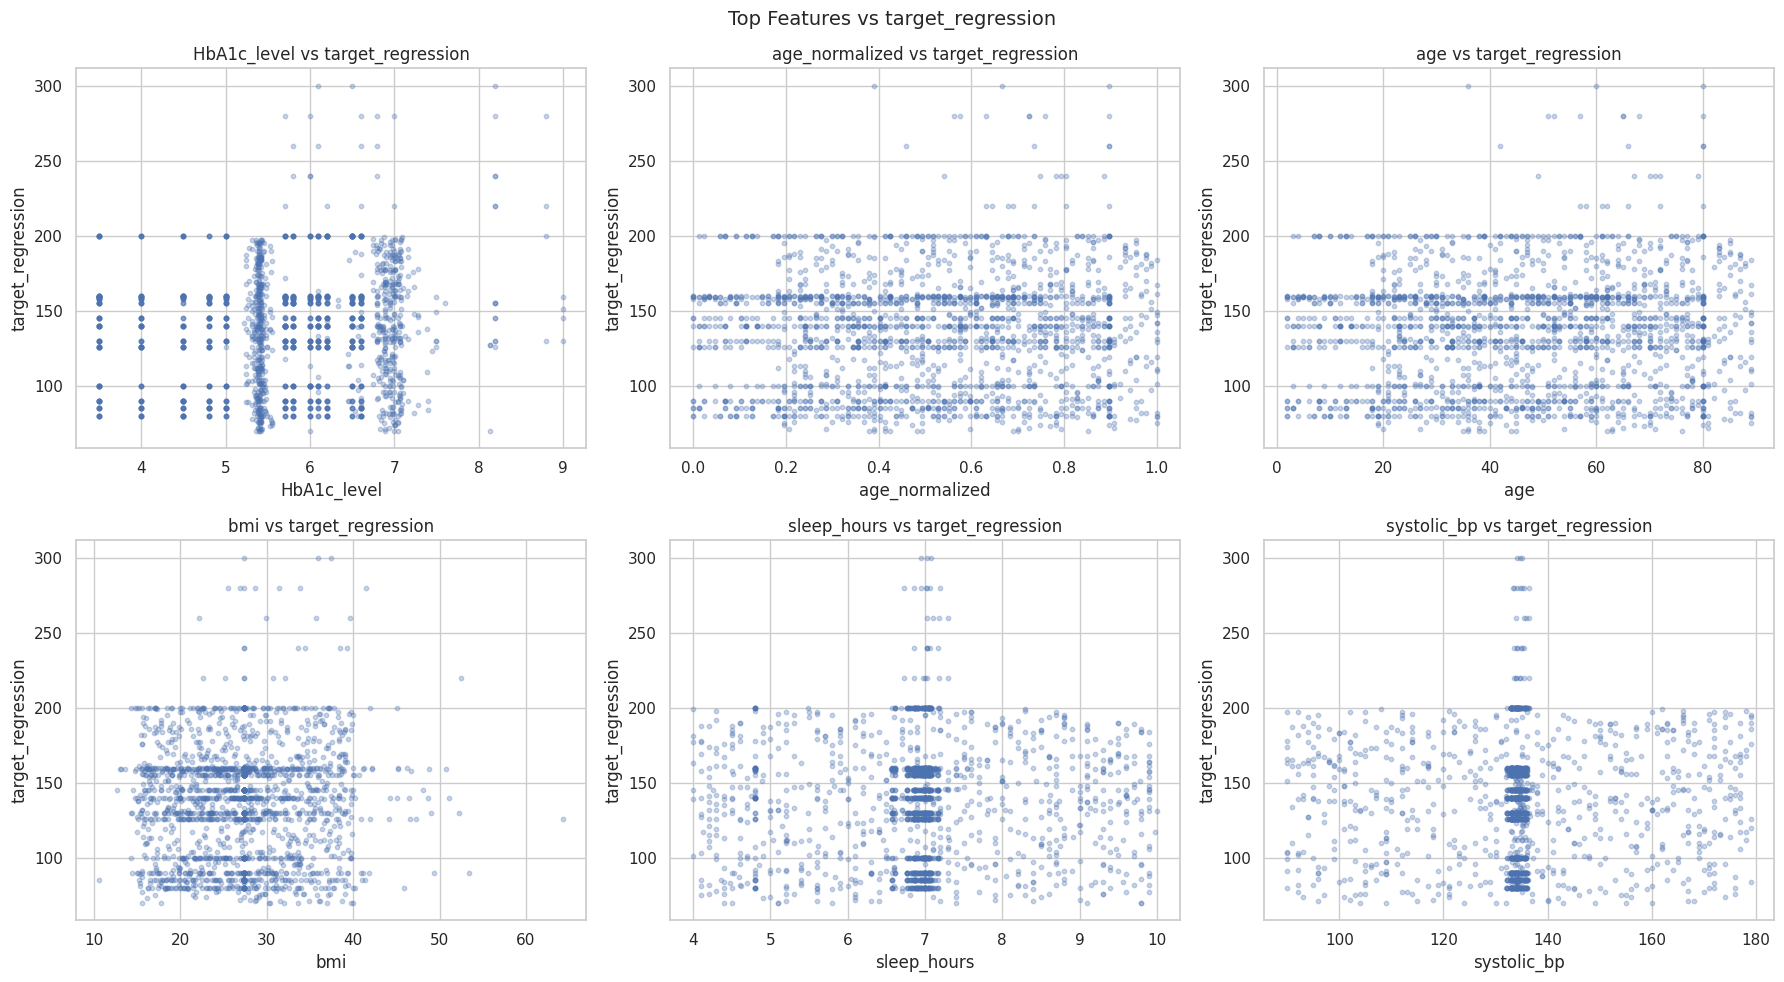

In [13]:
# Scatter: top correlated features vs target_regression
corr_with_target = df[numerical_cols].corr()['target_regression'].drop('target_regression').abs().sort_values(ascending=False)
print('Top correlations with target_regression:')
print(corr_with_target.head(10))

top_features = corr_with_target.head(6).index.tolist()
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(top_features):
    axes[i].scatter(df[col], df['target_regression'], alpha=0.3, s=10)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('target_regression')
    axes[i].set_title(f'{col} vs target_regression')

plt.suptitle('Top Features vs target_regression', fontsize=14)
plt.tight_layout()
plt.show()

#### Conclusões: Top Features vs `target_regression`

1. **Nenhuma feature tem relação linear expressiva com `target_regression`.** O valor máximo de correlação é |r| = 0.107 (`HbA1c_level`), muito abaixo do limiar convencional de correlação fraca (|r| = 0.3). Todos os scatter plots confirmam visualmente a ausência de tendência linear: os pontos distribuem-se em nuvens sem inclinação discernível.

2. **`HbA1c_level` é o melhor preditor, mas ainda insuficiente.** No seu scatter plot, observa-se que valores mais altos de HbA1c tendem ligeiramente a associar-se a valores mais altos de `target_regression`, mas a dispersão vertical é tão grande que essa tendência é quase invisível. O agrupamento em colunas verticais (valores discretos de HbA1c) reforça que muitas observações têm valores imputados por categoria clínica.

3. **`sleep_hours` e `systolic_bp` revelam imputação massiva nos scatter plots.** Ambos mostram uma concentração extrema de pontos numa banda vertical estreita, com `target_regression` a variar entre 70 e 300 nessa mesma banda, o que sugere que estas variáveis têm a maioria dos valores imputados e, por isso, pouco explicam do alvo.

4. **`target_regression` apresenta valores semidiscretos.** Nos scatter plots são visíveis bandas horizontais em valores redondos (90, 100, 130, 140, 160, 200), sugerindo que o próprio alvo de regressão tem uma distribuição discreta ou foi arredondado, o que limita ainda mais a capacidade dos modelos lineares contínuos de o aproximar.

### 2.6 Data Treatment

Com base na EDA, identificamos três features a remover antes da modelação:
- **`calcium_baseline`**: variância zero (único valor 9.42), confirmado pelo histograma e `nunique() == 1`;
- **`systolic_index`**: duplicado exato de `systolic_bp` (r = 1.000 na matriz de correlação);
- **`age_normalized`**: transformação linear de `age` (r = 1.000), que introduziria multicolinearidade perfeita nos modelos lineares.

In [14]:
# --- 1. Constant features (nunique == 1 is more robust than std == 0) ---
constant_cols = [c for c in numerical_cols if df[c].nunique() == 1]
print('Constant features (zero variance):', constant_cols)

# --- 2. Redundant features ---
# 2a. Exact duplicates (bit-for-bit identical columns)
redundant_cols = set()
num_list = list(numerical_cols)
for i in range(len(num_list)):
    for j in range(i + 1, len(num_list)):
        if num_list[j] not in redundant_cols and df[num_list[i]].equals(df[num_list[j]]):
            redundant_cols.add(num_list[j])
            print(f'  DUPLICATE : "{num_list[i]}" == "{num_list[j]}"  →  dropping "{num_list[j]}"')

# 2b. Perfect linear correlation (|r| >= 0.9999 catches derived/scaled columns)
corr_matrix = df[num_list].corr().abs()
for i in range(len(num_list)):
    for j in range(i + 1, len(num_list)):
        if num_list[j] not in redundant_cols and corr_matrix.iloc[i, j] >= 0.9999:
            redundant_cols.add(num_list[j])
            print(f'  CORR≈1.0  : "{num_list[i]}" ↔ "{num_list[j]}" (r={corr_matrix.iloc[i, j]:.8f})  →  dropping "{num_list[j]}"')

print('\nColumns to remove:', sorted(constant_cols + list(redundant_cols)))

Constant features (zero variance): ['calcium_baseline']
  DUPLICATE : "systolic_bp" == "systolic_index"  →  dropping "systolic_index"
  CORR≈1.0  : "age" ↔ "age_normalized" (r=1.00000000)  →  dropping "age_normalized"

Columns to remove: ['age_normalized', 'calcium_baseline', 'systolic_index']


Separar a deteção da aplicação permite rever a lista antes de eliminar as colunas. O resultado limpo é guardado em `df_clean`.

In [15]:
# --- 3. Apply treatment ---
cols_to_drop = list(set(constant_cols) | redundant_cols)
print('Columns to drop:', sorted(cols_to_drop))

df_clean = df.drop(columns=cols_to_drop)
print(f'\nOriginal shape : {df.shape}')
print(f'Cleaned shape  : {df_clean.shape}')

Columns to drop: ['age_normalized', 'calcium_baseline', 'systolic_index']

Original shape : (2000, 35)
Cleaned shape  : (2000, 32)


**Redundâncias escondidas e features derivadas.** A matriz de correlação só deteta redundância linear entre colunas alinhadas. Por isso, verificámos também:

- **`ldl_alternative`** tem exatamente os mesmos valores que `ldl`, mas por outra ordem (correlação ≈ 0). É uma versão baralhada de `ldl`, que não preserva a relação com o paciente: é, na prática, **uma feature de ruído**. Optámos por **mantê-la** de forma deliberada, para testar na secção 5 se os métodos de regularização a identificam como não informativa.
- **`age_level`** e **`bmi_level`** são discretizações de `age` e `bmi`. Contêm informação parcialmente redundante, mas não perfeitamente colinear (|r| < 1 após one-hot encoding), pelo que foram mantidas: a seleção por regularização decide qual das representações é mais útil.
- **`low_hdl_cholesterol`** e **`high_ldl_cholesterol`** são flags clínicas derivadas de `hdl`/`ldl`, mantidas pela mesma razão.
- **`blood_pressure`** é uma medida agregada da tensão arterial, mas não é uma combinação linear exata de `systolic_bp`/`diastolic_bp` (correlações baixas), pelo que não introduz multicolinearidade perfeita.

In [16]:
# --- 4. Hidden redundancy: ldl_alternative vs ldl ---
same_values = np.allclose(np.sort(df['ldl'].values), np.sort(df['ldl_alternative'].values))
print('ldl_alternative contém exatamente os mesmos valores que ldl (ordenados):', same_values)
print(f"Correlação de Pearson ldl vs ldl_alternative: {df['ldl'].corr(df['ldl_alternative']):.4f}")

# --- 5. Derived features: consistency with their source column ---
print('\nbmi_level vs bmi (min / max por categoria):')
print(df.groupby('bmi_level')['bmi'].agg(['min', 'max']).round(2))
print('\nage_level vs age (min / max por categoria):')
print(df.groupby('age_level')['age'].agg(['min', 'max']))
print(f"\nCorrelação blood_pressure vs systolic_bp:  {df['blood_pressure'].corr(df['systolic_bp']):.3f}")
print(f"Correlação blood_pressure vs diastolic_bp: {df['blood_pressure'].corr(df['diastolic_bp']):.3f}")

ldl_alternative contém exatamente os mesmos valores que ldl (ordenados): True
Correlação de Pearson ldl vs ldl_alternative: -0.0210

bmi_level vs bmi (min / max por categoria):
               min    max
bmi_level                
Normal       18.50  24.97
Obese        30.00  64.27
Overweight   25.00  29.98
Underweight  10.59  18.47

age_level vs age (min / max por categoria):
           min  max
age_level          
Mature      46   67
Middle      24   45
Senior      68   89
Young        2   23

Correlação blood_pressure vs systolic_bp:  0.007
Correlação blood_pressure vs diastolic_bp: 0.041


Persistimos o dataset limpo em disco para garantir reprodutibilidade e facilitar inspeção manual ou uso noutros contextos.

In [17]:
# Save cleaned dataset for external use
CLEANED_PATH = DATASET_PATH.replace('dataset_grupo_18.csv', 'dataset_grupo_18_cleaned.csv')
df_clean.to_csv(CLEANED_PATH, index=False)
print(f'Cleaned dataset saved to {CLEANED_PATH}')
print(f'Final shape: {df_clean.shape}')
print(f'Remaining features: {df_clean.columns.tolist()}')

Cleaned dataset saved to ../dataset_grupo_18_cleaned.csv
Final shape: (2000, 32)
Remaining features: ['age_level', 'gender', 'bmi_level', 'smoking', 'age', 'bmi', 'HbA1c_level', 'cholesterol', 'sleep_hours', 'triglycerides', 'physical_activity', 'family_history', 'stress_level', 'low_hdl_cholesterol', 'high_ldl_cholesterol', 'blood_pressure', 'sugar_consumption', 'crp_level', 'homocysteine_level', 'systolic_bp', 'diastolic_bp', 'alcohol_intake', 'salt_intake', 'heart_rate', 'hdl', 'ldl', 'education_level', 'employment_status', 'plasma_value', 'ldl_alternative', 'target_regression', 'target_class']


Estatísticas descritivas do dataset após tratamento confirmam que as features removidas já não estão presentes e que as distribuições das sobreviventes são as esperadas.

In [18]:
df_clean.select_dtypes(include=[np.number]).describe().T

,count,mean,std,min,25%,50%,75%,max
age,2000.0,46.778500,22.182120,2.000000,29.000000,47.000000,65.000000,89.000000
bmi,2000.0,27.097259,6.675740,10.590000,22.430000,27.320000,30.971278,64.270000
HbA1c_level,2000.0,5.712300,1.033372,3.500000,5.245652,5.700000,6.500000,9.000000
cholesterol,2000.0,223.494228,28.249128,150.000000,217.232323,225.000000,229.631579,299.000000
sleep_hours,2000.0,6.930174,1.154802,4.000000,6.770819,6.968389,7.080402,10.000000
triglycerides,2000.0,201.077147,64.646075,50.000000,149.733553,228.500000,251.281250,393.000000
blood_pressure,2000.0,150.123830,4.221680,121.000000,148.680000,149.713320,150.720942,180.000000
crp_level,2000.0,7.502463,0.951538,0.900569,7.312963,7.462859,7.824534,14.156036
homocysteine_level,2000.0,12.443702,0.935000,5.384979,12.287763,12.503725,12.691084,19.950612
systolic_bp,2000.0,134.460825,15.782950,90.000000,133.052402,134.167413,135.590248,179.000000


#### Conclusões: Data Treatment

O pipeline de tratamento de dados removeu **3 das 22 features numéricas originais**, reduzindo o dataset de (2000 × 35) para (2000 × 32):

| Passo | Features removidas | Critério | Evidência da EDA |
|---|---|---|---|
| Variância zero | `calcium_baseline` | nunique == 1 | Histograma com barra única em 9.42 |
| Redundância exata | `systolic_index` | r = 1.000 com `systolic_bp` | Matriz de correlação + boxplots idênticos |
| Correlação perfeita | `age_normalized` | r = 1.000 com `age` | Bloco vermelho escuro na matriz de correlação |

**Dataset limpo (2000 × 32):** mantém todas as features numéricas com variabilidade real, incluindo `age`, `bmi`, `HbA1c_level`, `cholesterol`, `triglycerides`, `alcohol_intake`, entre outras. As features com padrões de imputação massiva (pico nos histogramas), as features derivadas (`age_level`, `bmi_level`, flags de HDL/LDL) e `ldl_alternative` (versão baralhada de `ldl`) permanecem; o seu impacto nos modelos é avaliado na etapa de Feature Selection.

### 2.7 Conclusões da EDA

#### 2.7.1 Estatísticas Descritivas

As estatísticas descritivas (calculadas apenas sobre features numéricas, para evitar NaN de métricas inaplicáveis a categóricas) revelam uma população com perfil de risco cardiometabólico elevado:

| Observação | Valor | Interpretação clínica |
|---|---|---|
| `cholesterol` médio | 223.5 mg/dL | Acima do limiar borderline (≥ 200) |
| `triglycerides` médio | 201.1 mg/dL | Limiar de risco moderado (≥ 150) |
| `crp_level` médio | 7.5 | Inflamação vascular elevada (> 3) |
| `homocysteine_level` médio | 12.4 µmol/L | Risco cardiovascular (> 10) |
| `bmi` máximo | 64.3 kg/m² | Obesidade mórbida extrema — cauda longa à direita |
| `blood_pressure` std | 4.22 para amplitude 59 | Desvio-padrão anormalmente baixo — medida derivada/imputada |
| `calcium_baseline` | sempre 9.42 | **Variância zero** — sem informação discriminante, removida |

---

#### 2.7.2 Análise Univariada

**Numérica**
**Padrões principais:**
- **Imputação massiva**: `cholesterol`, `blood_pressure`, `systolic_bp`, `diastolic_bp`, `salt_intake`, `heart_rate`, `hdl`, `ldl`, `ldl_alternative` apresentam uma barra central dominante com caudas muito reduzidas, indicando que a maioria dos valores foi imputada por médias populacionais.
- **Bimodal**: `triglycerides`, `crp_level`, `homocysteine_level` e `alcohol_intake` apresentam dois picos distintos, sugerindo dois subgrupos populacionais com perfis de risco diferentes.
- **`plasma_value`**: única feature com distribuição genuinamente normal e contínua.
- **`bmi`**: assimétrica à direita com cauda até 64.3 kg/m².
- **`calcium_baseline`**: barra única em 9.42 → variância zero → removida.

**Categóricas** 
**Desequilíbrio crítico de `target_class`:**

```
N  → 1450  (72.5%)   ← classe maioritária
DI →  467  (23.4%)
HT →   83  ( 4.1%)   ← classe minoritária severa
```

> Um classificador que preveja sempre *N* obtém **72.5% de accuracy** sem aprender nada. Métricas de avaliação devem incluir **F1 macro** e **recall por classe**, não apenas accuracy. `StratifiedKFold` é obrigatório para preservar as proporções em todos os folds.

---

#### 2.7.3 Análise Bivariada

**Matriz de correlação (inclui `target_class`):**
Pares redundantes confirmados: `systolic_bp`/`systolic_index` (r = 1.000) e `age`/`age_normalized` (r = 1.000). Restantes correlações entre features: |r| < 0.15 (a imputação massiva atenua as correlações). `target_class` (DI=0, HT=1, N=2) mostra correlações negativas com `age` e `HbA1c_level`: valores mais elevados associam-se às classes de doença (DI e HT, inteiros menores), o que confirma os boxplots. A correlação com a codificação inteira é fraca (|r| < 0.15), mas a análise por classe (one-hot) mostra que `HbA1c_level` está fortemente associado a DI (r = 0.64) e `triglycerides` negativamente a DI (r = -0.28); nenhuma feature numérica tem associação relevante com HT (máx. |r| = 0.15, `age`).

**Boxplots vs `target_class`:**
- `age` e `HbA1c_level` são os melhores discriminadores visuais: medianas distintas entre N, DI e HT.
- `bmi` discrimina DI das restantes classes.
- A classe DI apresenta IQR sistematicamente mais largo do que N e HT em múltiplas features, revelando maior presença de medições reais (vs. imputadas).

**Correlações com `target_regression` todas fracas:**

| Feature | \|r\| |
|---|---|
| `HbA1c_level` | **0.107** ← melhor preditor |
| `age` | 0.054 |
| `bmi` | 0.036 |
| `sleep_hours` | 0.027 |
| `systolic_bp` | 0.018 |
| `homocysteine_level` | 0.018 |
| `alcohol_intake` | 0.015 |

> O limiar convencional de correlação fraca é |r| = 0.3. **Nenhuma feature sequer o atinge.** Os scatter plots confirmam ausência de tendências lineares claras e revelam que `target_regression` tem valores semidiscretos (bandas horizontais em valores redondos), o que limita ainda mais os modelos lineares. Os R² baixos são uma propriedade do dataset, não uma falha metodológica.

---

#### 2.7.4 Tratamento de Dados

**Remoção de features não informativas/redundantes (35 → 32 colunas):**

| Feature removida | Motivo |
|---|---|
| `calcium_baseline` | Variância zero (valor único = 9.42) — zero poder discriminante |
| `systolic_index` | Duplicado exato de `systolic_bp` (r = 1.000) |
| `age_normalized` | Transformação linear de `age` (r = 1.000) — preferível manter a escala original |

`ldl_alternative` (versão baralhada de `ldl`) foi identificada como feature de ruído, mas mantida deliberadamente para avaliar se a seleção por regularização a deteta (secção 5).

**Valores em falta:** nenhum encontrado: nem NaN reais nem strings NaN ocultas nas categóricas. Dataset completamente preenchido.

---

#### 2.7.5 Dataset Final

O dataset exportado (`dataset_grupo_18_cleaned.csv`) tem **2000 × 32**:

| Tipo | Features |
|---|---|
| **Categóricas (12)** | `age_level`, `gender`, `bmi_level`, `smoking`, `physical_activity`, `family_history`, `stress_level`, `low_hdl_cholesterol`, `high_ldl_cholesterol`, `sugar_consumption`, `education_level`, `employment_status` |
| **Numéricas (18)** | `age`, `bmi`, `HbA1c_level`, `cholesterol`, `sleep_hours`, `triglycerides`, `blood_pressure`, `crp_level`, `homocysteine_level`, `systolic_bp`, `diastolic_bp`, `alcohol_intake`, `salt_intake`, `heart_rate`, `hdl`, `ldl`, `plasma_value`, `ldl_alternative` |
| **Alvos (2)** | `target_regression`, `target_class` |

**Implicações para os passos seguintes:**
1. **Regressão**: correlações lineares com `target_regression` são todas fracas (max |r| = 0.107) e o alvo é semidiscreto → esperar R² baixos nos modelos lineares.
2. **Classificação**: desequilíbrio severo (72.5% / 23.4% / 4.1%) → usar `StratifiedKFold` + F1 macro como métrica principal.
3. **Feature selection**: as features com imputação massiva e a feature de ruído `ldl_alternative` deverão receber coeficientes baixos (ou nulos) na regularização L1, L2 e Elastic Net (secção 5).

---
### 2.8 Pré-processamento comum

Codificação de `df_clean` uma única vez, para todas as tarefas de aprendizagem supervisionada.

Antes das secções de modelação, codificamos as features categóricas com `pd.get_dummies(drop_first=True)`, que cria colunas binárias sem assumir ordem entre categorias (ao contrário do `LabelEncoder`) e evita a multicolinearidade perfeita das variáveis dummy. O `target_class` é codificado separadamente com `LabelEncoder` (DI=0, HT=1, N=2) para compatibilidade com os classificadores do sklearn. A normalização (`StandardScaler`) é sempre ajustada apenas nos dados de treino de cada partição, nas secções seguintes.

In [19]:
_cat_feature_cols = [
    col for col in df_clean.select_dtypes(exclude=[np.number]).columns
    if col not in ['target_regression', 'target_class']
]
df_enc = pd.get_dummies(df_clean, columns=_cat_feature_cols,
                        drop_first=True, dtype=int)

# Encode target_class as integers for sklearn classifiers
df_enc['target_class'] = LabelEncoder().fit_transform(
    df_clean['target_class'].astype(str)
)

# Feature list (excludes both targets)
FEATURES = [c for c in df_enc.columns
            if c not in ['target_regression', 'target_class']]
feature_names = np.array(FEATURES)

print(f'Features ({len(FEATURES)}): {FEATURES}')
print('Class distribution:', df_enc['target_class'].value_counts().to_dict())


Features (40): ['age', 'bmi', 'HbA1c_level', 'cholesterol', 'sleep_hours', 'triglycerides', 'blood_pressure', 'crp_level', 'homocysteine_level', 'systolic_bp', 'diastolic_bp', 'alcohol_intake', 'salt_intake', 'heart_rate', 'hdl', 'ldl', 'plasma_value', 'ldl_alternative', 'age_level_Middle', 'age_level_Senior', 'age_level_Young', 'gender_Male', 'bmi_level_Obese', 'bmi_level_Overweight', 'bmi_level_Underweight', 'smoking_Former', 'smoking_Never', 'physical_activity_Low', 'physical_activity_Moderate', 'family_history_Yes', 'stress_level_Low', 'stress_level_Medium', 'low_hdl_cholesterol_Yes', 'high_ldl_cholesterol_Yes', 'sugar_consumption_Low', 'sugar_consumption_Medium', 'education_level_Secondary', 'education_level_Tertiary', 'employment_status_Retired', 'employment_status_Unemployed']
Class distribution: {2: 1450, 0: 467, 1: 83}


---
## 3. Regression: Predicting `target_regression`

Define o alvo de regressão, cria a matriz de features como DataFrame (para seleção por nome de coluna) e divide em treino/teste com proporção 80/20. O `StandardScaler` é ajustado exclusivamente no conjunto de treino (`fit_transform`) e aplicado por transformação ao conjunto de teste (`transform`), evitando que estatísticas do teste influenciem a normalização. Para a Regressão Linear Ordinária, a escala não afeta o R² nem o RMSE, mas garante consistência com o pipeline de validação cruzada.

In [20]:
y_reg = df_enc['target_regression'].values
X_reg = df_enc[FEATURES]

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=RANDOM_STATE
)

# Fit scaler on training data only to avoid leakage
scaler_r = StandardScaler()
X_train_r_scaled = pd.DataFrame(
    scaler_r.fit_transform(X_train_r),
    columns=X_train_r.columns,
    index=X_train_r.index
)
X_test_r_scaled = pd.DataFrame(
    scaler_r.transform(X_test_r),
    columns=X_test_r.columns,
    index=X_test_r.index
)

print(f'Train: {X_train_r_scaled.shape} | Test: {X_test_r_scaled.shape}')


Train: (1600, 40) | Test: (400, 40)


`evaluate_reg` centraliza o cálculo das três métricas para garantir consistência entre modelos:
- **R²**: proporção da variância explicada; 0 equivale a prever a média, negativo é pior do que a média;
- **MAE**: erro médio absoluto, na mesma unidade que o alvo, robusto a outliers;
- **RMSE**: penaliza mais os erros grandes, útil quando esses erros são mais prejudiciais.

In [21]:
def evaluate_reg(name, y_true, y_pred):
    r2   = r2_score(y_true, y_pred)
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    print(f'[{name}]  R²={r2:.4f}  MAE={mae:.4f}  RMSE={rmse:.4f}')
    return {'Model': name, 'R²': r2, 'MAE': mae, 'RMSE': rmse}

### 3.1 Simple Linear Regression

Treinou-se uma Regressão Linear Simples para cada feature individualmente e ordenam-se os resultados por **R² médio em validação cruzada (5-fold) calculado exclusivamente no conjunto de treino**. Usar o conjunto de teste para este ranking introduziria data leakage: o modelo final seria avaliado no mesmo conjunto que influenciou a seleção de features.

In [22]:
# Rank features by mean 5-fold CV R² on training data only.
# Using the test set here would contaminate feature selection.
reg_results_simple = []
for feat in FEATURES:
    m = LinearRegression()
    cv_r2 = cross_val_score(m, X_train_r_scaled[[feat]], y_train_r,
                            cv=5, scoring='r2')
    reg_results_simple.append({'Feature': feat, 'R² (CV)': np.mean(cv_r2)})

results_simple_df = pd.DataFrame(reg_results_simple).sort_values('R² (CV)', ascending=False)
results_simple_df.head(10)


,Feature,R² (CV)
2,HbA1c_level,0.006011
0,age,-0.000337
20,age_level_Young,-0.002802
4,sleep_hours,-0.002832
19,age_level_Senior,-0.003145
37,education_level_Tertiary,-0.003248
35,sugar_consumption_Medium,-0.003269
9,systolic_bp,-0.003350
1,bmi,-0.003738
38,employment_status_Retired,-0.003788


Treinou-se o modelo final com a melhor feature e visualizamos a relação entre os valores reais e preditos. O scatter plot permite confirmar se a relação é genuinamente linear ou se há padrões (heterocedasticidade, tendência residual) que o modelo linear não consegue capturar.

Best single feature: HbA1c_level
[Simple LR]  R²=0.0083  MAE=30.8520  RMSE=38.3962


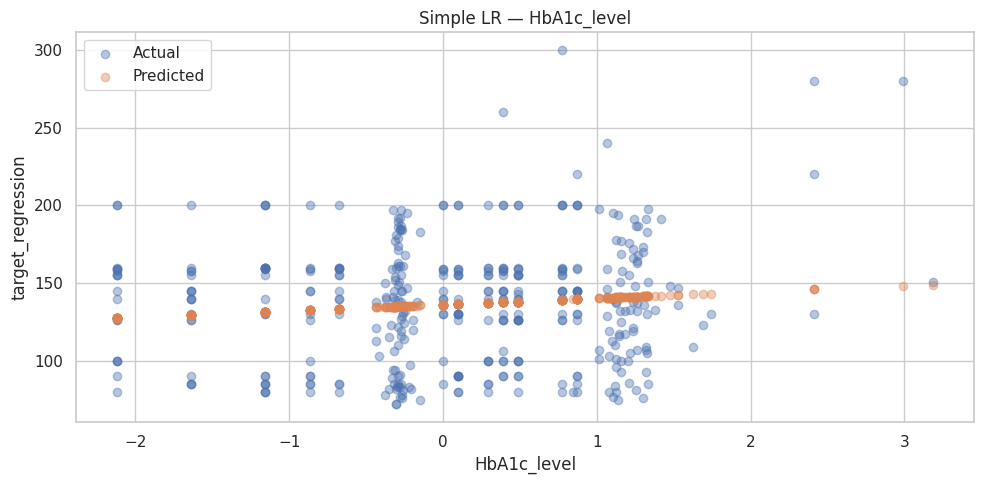

In [23]:
best_feat = results_simple_df.iloc[0]['Feature']
print(f'Best single feature: {best_feat}')

model_slr = LinearRegression()
model_slr.fit(X_train_r_scaled[[best_feat]], y_train_r)
y_pred_slr = model_slr.predict(X_test_r_scaled[[best_feat]])
reg_metrics = [evaluate_reg('Simple LR', y_test_r, y_pred_slr)]

plt.scatter(X_test_r_scaled[best_feat], y_test_r, alpha=0.4, label='Actual')
plt.scatter(X_test_r_scaled[best_feat], y_pred_slr, alpha=0.4, label='Predicted')
plt.xlabel(best_feat)
plt.ylabel('target_regression')
plt.legend()
plt.title(f'Simple LR — {best_feat}')
plt.tight_layout()
plt.show()

O gráfico mostra claramente que o modelo não consegue fazer previsões úteis com apenas esta feature. Os pontos cor de laranja (valores previstos) estão quase todos alinhados na horizontal, à volta de 130-140 — o modelo prevê praticamente o mesmo valor para todos os pacientes, independentemente do nível de HbA1c. Isto acontece porque a correlação entre HbA1c_level e target_regression é muito fraca (|r| ≈ 0.11): a variação no HbA1c explica menos de 1% da variação no target (R² ≈ 0.008). O alvo também assume valores discretos bem definidos (por exemplo 90, 100, 130, 140, 160, 200), o que torna ainda mais difícil para uma regressão linear simples se ajustar. Em suma, uma única feature não chega para prever este alvo — é necessário combinar várias variáveis, como faremos na secção seguinte.

### 3.2 Multiple Linear Regression

Regressão Linear Múltipla com todas as features como referência. R² negativo ou próximo de zero indica que adicionar mais variáveis não ajuda.

In [24]:
model_mlr_all = LinearRegression()
model_mlr_all.fit(X_train_r_scaled, y_train_r)
reg_metrics.append(evaluate_reg('Multiple LR (all features)', y_test_r, model_mlr_all.predict(X_test_r_scaled)))

[Multiple LR (all features)]  R²=-0.0344  MAE=31.7676  RMSE=39.2133


Regressão Linear Múltipla com as top-N features do ranking da Regressão Linear Simples (R² médio em CV no treino). A seleção univariada é uma heurística simples, mas eficaz quando as features são relativamente independentes (como se viu na matriz de correlação). Não garante o subconjunto ótimo: features com R² univariado alto podem ser redundantes entre si.

#### Determinação do Top-N ótimo

Para evitar data leakage, o valor ótimo de N é determinado por **validação cruzada de 5 folds exclusivamente no conjunto de treino** (`X_train_r`/`y_train_r`). Usar `X_test_r` para escolher N introduziria um enviesamento positivo: o modelo final seria avaliado no mesmo conjunto que influenciou a sua seleção. O N com melhor **R² médio em CV** é adotado como `TOP_N`; o conjunto de teste é reservado para a avaliação final dos três modelos.

Melhor N por R² (CV)  : 2  -> R²=0.0077
Melhor N por RMSE (CV): 2  -> RMSE=36.8864
Melhor N por MAE  (CV): 1  -> MAE=29.8302
TOP_N escolhido (melhor R² CV): 2


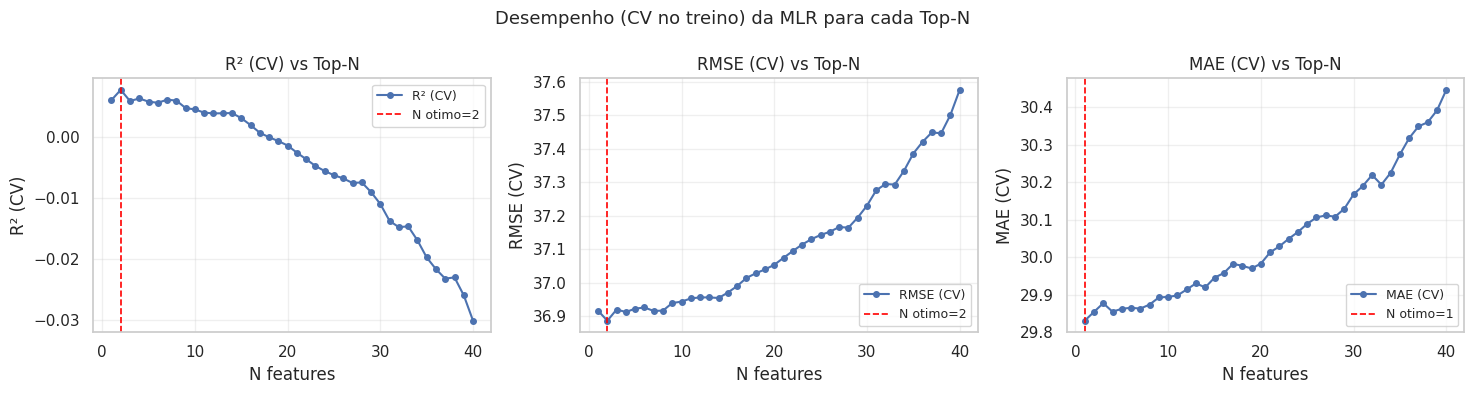

In [25]:
topn_metrics = []
all_feats_ranked = results_simple_df['Feature'].tolist()

for n in range(1, len(all_feats_ranked) + 1):
    feats_n = all_feats_ranked[:n]
    _m = LinearRegression()
    r2_cv   = cross_val_score(_m, X_train_r_scaled[feats_n], y_train_r,
                              cv=5, scoring='r2')
    rmse_cv = cross_val_score(_m, X_train_r_scaled[feats_n], y_train_r,
                              cv=5, scoring='neg_root_mean_squared_error')
    mae_cv  = cross_val_score(_m, X_train_r_scaled[feats_n], y_train_r,
                              cv=5, scoring='neg_mean_absolute_error')
    topn_metrics.append({
        'N': n,
        'R² (CV)': np.mean(r2_cv),
        'RMSE (CV)': -np.mean(rmse_cv),
        'MAE (CV)': -np.mean(mae_cv),
    })

topn_df = pd.DataFrame(topn_metrics).set_index('N')

TOP_N       = int(topn_df['R² (CV)'].idxmax())
best_rmse_n = int(topn_df['RMSE (CV)'].idxmin())
best_mae_n  = int(topn_df['MAE (CV)'].idxmin())

print(f'Melhor N por R² (CV)  : {TOP_N}  -> R²={topn_df.loc[TOP_N, "R² (CV)"]:.4f}')
print(f'Melhor N por RMSE (CV): {best_rmse_n}  -> RMSE={topn_df.loc[best_rmse_n, "RMSE (CV)"]:.4f}')
print(f'Melhor N por MAE  (CV): {best_mae_n}  -> MAE={topn_df.loc[best_mae_n, "MAE (CV)"]:.4f}')
print(f'TOP_N escolhido (melhor R² CV): {TOP_N}')

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric, best_n in zip(
    axes, ['R² (CV)', 'RMSE (CV)', 'MAE (CV)'], [TOP_N, best_rmse_n, best_mae_n]
):
    topn_df[metric].plot(ax=ax, marker='o', markersize=4, linewidth=1.5)
    ax.axvline(best_n, color='red', linestyle='--', linewidth=1.2,
               label=f'N otimo={best_n}')
    ax.set_title(f'{metric} vs Top-N')
    ax.set_xlabel('N features')
    ax.set_ylabel(metric)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

plt.suptitle('Desempenho (CV no treino) da MLR para cada Top-N', fontsize=13)
plt.tight_layout()
plt.show()

#### Conclusões: Top-N ótimo
O gráfico mostra o padrão clássico de overfitting por excesso de features de ruído. As features são acrescentadas pela ordem do ranking da Simple LR (da mais útil para a menos útil), por isso cada ponto à direita junta uma feature com menos sinal do que a anterior.

1. **O desempenho é máximo com N = 2** (`HbA1c_level` e `age`): R² (CV) = 0.0077 e RMSE (CV) = 36.89. Estas são as únicas features com algum sinal linear em relação ao alvo.

2. **Entre N ≈ 3 e N ≈ 15 o desempenho estabiliza.** As features adicionadas não têm relação com o alvo e recebem coeficientes próximos de zero, pelo que pouco alteram as previsões.

3. **A partir de N ≈ 15, o desempenho degrada-se de forma contínua (overfitting).** Cada feature adicional introduz um coeficiente ajustado a correlações espúrias do treino, o que aumenta a variância das previsões sem reduzir o viés. O R² torna-se negativo por volta de N ≈ 18 e chega a -0.030 com as 40 features, valor coerente com o R² = -0.034 obtido no conjunto de teste.

4. **O MAE indica N = 1 e o R²/RMSE indicam N = 2.** As métricas quadráticas dão mais peso aos erros grandes, que `age` reduz ligeiramente; o erro típico (MAE) não melhora. A diferença entre N = 1 e N = 2 é, por isso, marginal.

5. **As diferenças absolutas são pequenas:** o RMSE varia entre 36.9 e 37.6, para um alvo com desvio-padrão de 37.4. Mesmo o melhor modelo tem capacidade preditiva quase nula. O gráfico confirma que adicionar features degrada o modelo, mas nenhum subconjunto de features torna a regressão linear útil para este alvo.

In [26]:
top_feats = all_feats_ranked[:TOP_N]
print(f'Top {TOP_N} features: {top_feats}')

model_mlr_top = LinearRegression()
model_mlr_top.fit(X_train_r_scaled[top_feats], y_train_r)
reg_metrics.append(evaluate_reg(
    f'Multiple LR (top {TOP_N})',
    y_test_r,
    model_mlr_top.predict(X_test_r_scaled[top_feats])
))


Top 2 features: ['HbA1c_level', 'age']
[Multiple LR (top 2)]  R²=0.0087  MAE=30.9139  RMSE=38.3887


### 3.3 Comparação e Discussão

Tabela e gráfico comparativos dos três modelos permitem verificar se o modelo múltiplo melhora o simples, identificar trade-offs entre métricas (ex.: MAE melhorou mas RMSE piorou), e documentar os resultados de forma clara.

,R²,MAE,RMSE
Model,,,
Simple LR,0.008299,30.851973,38.396230
Multiple LR (all features),-0.034357,31.767593,39.213307
Multiple LR (top 2),0.008686,30.913875,38.388733


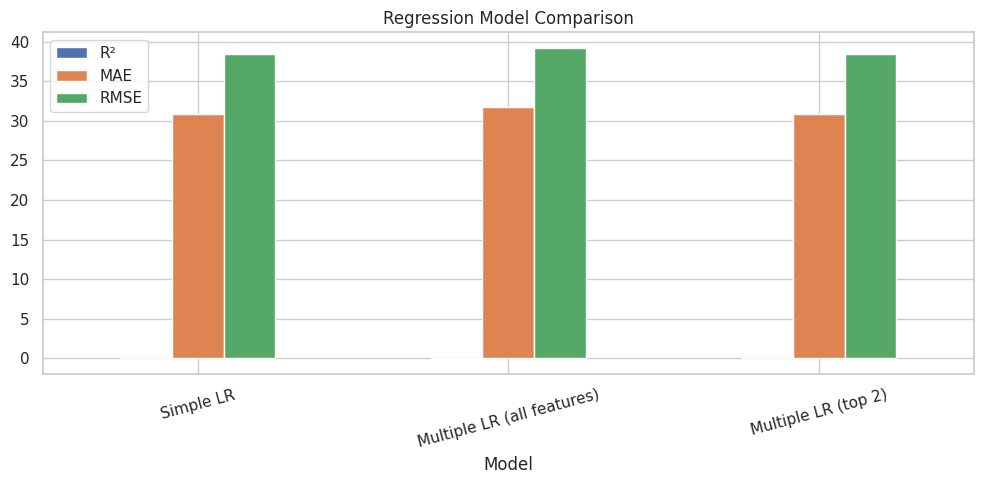

In [27]:
reg_metrics_df = pd.DataFrame(reg_metrics).set_index('Model')
display(reg_metrics_df)

reg_metrics_df[['R²', 'MAE', 'RMSE']].plot(kind='bar', figsize=(10, 5))
plt.title('Regression Model Comparison')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

#### Comparação dos três modelos

| Modelo | R² | MAE | RMSE | Observação |
|---|---|---|---|---|
| Simple LR (`HbA1c_level`) | 0.0083 | **30.85** | 38.40 | Baseline: 1 feature |
| Multiple LR (todas as 40 features) | **-0.0344** | 31.77 | 39.21 | Pior do que prever a média |
| Multiple LR (top-2: `HbA1c_level`, `age`) | **0.0087** | 30.91 | **38.39** | Praticamente igual à Simple LR |

Valores no conjunto de teste (20%). O TOP_N = 2 foi escolhido por validação cruzada no treino.

---

#### Porque é que o modelo com todas as features tem R² negativo?

O R² é definido como:

```
R² = 1 - SS_res / SS_tot

SS_res = soma dos quadrados dos resíduos do modelo
SS_tot = soma dos quadrados dos desvios em relação à média de y
```

Quando `SS_res > SS_tot`, o modelo comete **mais erro do que um preditor constante** (que previsse sempre a média de `y_train`), resultando em R² negativo.

Isto acontece aqui por três razões cumulativas:

1. **Sinal linear muito fraco.** A correlação máxima de qualquer feature com `target_regression` é |r| = 0.107 (`HbA1c_level`). Todas as restantes features têm |r| < 0.06, ou seja, são essencialmente ruído em relação ao alvo.

2. **Overfitting com muitas features de ruído.** Após `pd.get_dummies`, o dataset tem 40 features. A regressão linear sem regularização ajusta-se a correlações espúrias no conjunto de treino que não existem na população real. No conjunto de teste, esses coeficientes amplificam o erro em vez de o reduzir.

3. **`target_regression` é semidiscreto.** Como observado nos scatter plots da EDA, o alvo apresenta valores arredondados (90, 100, 130, 140, 160, 200), o que dificulta adicionalmente o ajuste de um modelo linear contínuo.

**Este comportamento não é um erro metodológico: é evidência empírica de que a relação linear entre as features disponíveis e `target_regression` é, no máximo, muito fraca.**

---

#### Porque é que o modelo top-N supera o modelo com todas as features?

O modelo **Multiple LR (top-N)** seleciona, por validação cruzada exclusivamente no conjunto de treino, o número N de features que maximiza o R² médio em CV (N = 2). Ao excluir as features de ruído, evita que os seus coeficientes perturbem o ajuste e generaliza melhor do que o modelo com todas as features.

O facto de o modelo com todas as features ter R² negativo, enquanto o top-2 tem R² positivo (ainda que próximo de zero), **valida a necessidade de seleção de features**: neste dataset, adicionar mais features degrada ativamente o modelo.

Face à Simple LR, contudo, o ganho é desprezável: o R² sobe de 0.0083 para 0.0087 e o RMSE desce 0.01, mas o MAE piora ligeiramente (30.85 → 30.91). Adicionar `age` a `HbA1c_level` não acrescenta informação útil, o que é coerente com |r| = 0.054 entre `age` e o alvo.

**Modelo selecionado:** dado que as diferenças entre a Simple LR e a Multiple LR top-2 são residuais, a Simple LR com `HbA1c_level` é preferível pelo princípio da parcimónia (mesmo desempenho com menos features).

---

#### Conclusão geral

Os valores de R² próximos de zero em todos os modelos refletem uma propriedade do dataset, não uma falha metodológica:

- As features disponíveis têm, no máximo, uma relação linear muito fraca com `target_regression` (máx. |r| = 0.107, muito abaixo do limiar de correlação fraca |r| = 0.3).
- Modelos não lineares (árvores de decisão, redes neuronais) poderiam capturar relações que a regressão linear não consegue.
- A regressão linear é o ponto de partida obrigatório para estabelecer um baseline: qualquer modelo mais complexo deve superar estes resultados para justificar a sua complexidade adicional.

#### Concordância com a EDA

Os resultados da regressão confirmam ponto a ponto as previsões feitas na secção 2.7.5:

| Previsão da EDA | Resultado observado | Concordância |
|---|---|---|
| Max \|r\| = 0.107 (`HbA1c_level`) → esperar R² baixos | R² = 0.0083 (SLR), -0.0344 (MLR todas as features), 0.0087 (top-2) | ✓ Confirmada |
| `target_regression` semidiscreto → dificulta ajuste linear contínuo | Scatter plot mostra previsões concentradas em ~130–140 independentemente do valor de HbA1c | ✓ Confirmada |
| Features com imputação massiva introduzem ruído | MLR com todas as features piora face à média (R² < 0); top-N ao excluir ruído recupera R² positivo | ✓ Confirmada |
| `HbA1c_level` é o melhor preditor individual | Selecionada como best feature na Simple LR, consistente com o ranking da EDA | ✓ Confirmada |

Os R² próximos de zero não são uma surpresa nem um problema metodológico: foram explicitamente previstos na EDA com base nas correlações observadas. O pipeline de regressão cumpre o seu objetivo de estabelecer um baseline e fornecer evidência empírica de que os modelos lineares têm capacidade preditiva quase nula para `target_regression` neste dataset.

---
## 4. Classification: Predicting `target_class`

Métodos: **Logistic Regression** e **LDA**  
Resampling: Holdout | CV k=5 | CV k=10 | LOOCV | Bootstrap  
`StratifiedKFold` é usado em todo o capítulo para preservar as proporções de classes, dado o desequilíbrio severo (N=72.5%, DI=23.4%, HT=4.1%).

**Métrica principal: F1-score macro**  
Com um desequilíbrio tão acentuado, a **accuracy é uma métrica enganosa**: um classificador que preveja sempre a classe maioritária (N) obteria **72.5% de accuracy sem aprender nada**. O **F1-score macro** calcula o F1 por classe e faz a média aritmética, penalizando igualmente os erros em todas as classes, independentemente da sua frequência. Assim, um modelo que ignore completamente DI e HT obteria um F1 macro próximo de 0.28 em vez de 72.5%, tornando o problema visivelmente mais difícil. A accuracy é mantida para referência e comparabilidade, mas o F1 macro é o critério de decisão principal.

Inicializou-se os dois classificadores. A **Regressão Logística** é um modelo linear probabilístico, interpretável pelos seus coeficientes, com `max_iter=1000` para garantir convergência com features categóricas encodadas. O **LDA** assume distribuições gaussianas por classe com covariâncias iguais e maximiza a separação entre classes. Comparar os dois permite perceber se a suposição gaussiana do LDA é adequada para estes dados.

In [28]:
# Classification targets and features
y_class = df_enc['target_class'].values
X_clf   = df_enc[FEATURES].values  # unscaled; scaling done per split

clf_models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    'LDA': LinearDiscriminantAnalysis()
}

def clf_pipe(name):
    """Fresh pipeline (StandardScaler + cloned model) for each CV call."""
    return make_pipeline(StandardScaler(), clone(clf_models[name]))

clf_results = []

def record_clf(model_name, method, acc_scores, f1_scores):
    clf_results.append({
        'Model': model_name,
        'Method': method,
        'Mean Accuracy': np.mean(acc_scores),
        'Acc Std': np.std(acc_scores),
        'Mean F1 (macro)': np.mean(f1_scores),
        'F1 Std': np.std(f1_scores),
    })


### 4.1 Holdout

Divisão treino/teste (80/20) com `stratify=y_class`, para preservar as proporções de classes em ambos os conjuntos, o que é crítico com um desequilíbrio severo (HT=4.1%). O scaler é ajustado apenas no conjunto de treino. A matriz de confusão complementa as métricas: um modelo que preveja sempre N obtém 72.5% de accuracy, mas um F1 macro de apenas ~0.28, evidenciando que a accuracy, por si só, é enganosa neste dataset.

Logistic Regression — Holdout  Accuracy: 0.9250  |  F1 macro: 0.6283
              precision    recall  f1-score   support

           0       0.93      0.94      0.93        93
           1       0.00      0.00      0.00        17
           2       0.93      0.98      0.95       290

    accuracy                           0.93       400
   macro avg       0.62      0.64      0.63       400
weighted avg       0.89      0.93      0.91       400



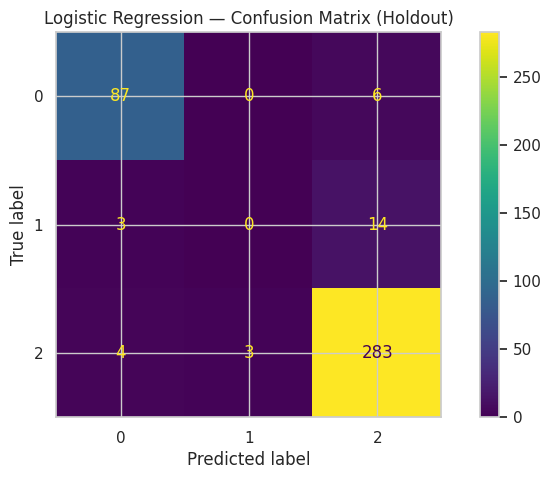

LDA — Holdout  Accuracy: 0.8975  |  F1 macro: 0.6332
              precision    recall  f1-score   support

           0       0.93      0.84      0.88        93
           1       0.14      0.06      0.08        17
           2       0.91      0.97      0.93       290

    accuracy                           0.90       400
   macro avg       0.66      0.62      0.63       400
weighted avg       0.88      0.90      0.89       400



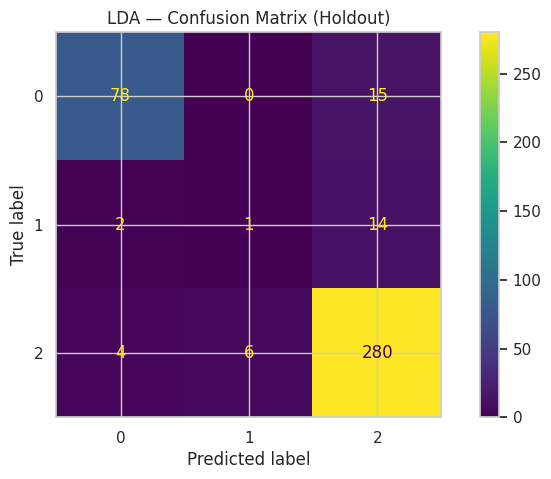

In [29]:
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_clf, y_class, test_size=0.2, stratify=y_class, random_state=RANDOM_STATE
)

# Fit scaler on training data only
scaler_c = StandardScaler()
X_train_c_sc = scaler_c.fit_transform(X_train_c)
X_test_c_sc  = scaler_c.transform(X_test_c)

for name, model in clf_models.items():
    model.fit(X_train_c_sc, y_train_c)
    y_pred = model.predict(X_test_c_sc)
    acc = accuracy_score(y_test_c, y_pred)
    f1  = f1_score(y_test_c, y_pred, average='macro', zero_division=0)
    record_clf(name, 'Holdout', [acc], [f1])
    print(f'{name} — Holdout  Accuracy: {acc:.4f}  |  F1 macro: {f1:.4f}')
    print(classification_report(y_test_c, y_pred, zero_division=0))
    disp = ConfusionMatrixDisplay(confusion_matrix(y_test_c, y_pred))
    disp.plot()
    plt.title(f'{name} — Confusion Matrix (Holdout)')
    plt.show()


### 4.2 Cross-Validation: Stratified k-Fold (k=5 e k=10)

`StratifiedKFold` garante que cada fold conserva as proporções originais da classe.

O Stratified K-Fold avalia os modelos em k partições, mantendo as proporções de classes em cada fold. O scaler é ajustado dentro de cada fold via Pipeline, evitando que informação do fold de teste influencie a normalização. São reportados tanto a accuracy como o F1 macro; o F1 é a métrica principal, dado o desequilíbrio de classes.

In [30]:
for k in [5, 10]:
    cv_strat = StratifiedKFold(n_splits=k, shuffle=True, random_state=RANDOM_STATE)
    for name in clf_models:
        acc_scores = cross_val_score(clf_pipe(name), X_clf, y_class,
                                    cv=cv_strat, scoring='accuracy')
        f1_scores  = cross_val_score(clf_pipe(name), X_clf, y_class,
                                    cv=cv_strat, scoring='f1_macro')
        record_clf(name, f'CV k={k} (Stratified)', acc_scores, f1_scores)
        print(f'{name} — CV k={k}:  '
              f'Acc={np.mean(acc_scores):.4f}+-{np.std(acc_scores):.4f}  '
              f'F1={np.mean(f1_scores):.4f}+-{np.std(f1_scores):.4f}')


Logistic Regression — CV k=5:  Acc=0.9080+-0.0081  F1=0.6160+-0.0088
LDA — CV k=5:  Acc=0.8865+-0.0138  F1=0.6320+-0.0224


Logistic Regression — CV k=10:  Acc=0.9095+-0.0135  F1=0.6167+-0.0227
LDA — CV k=10:  Acc=0.8865+-0.0155  F1=0.6279+-0.0483


### 4.3 Leave-One-Out Cross-Validation (LOOCV)

O LOOCV treina com n-1 instâncias e avalia na que ficou de fora, repetindo o processo para cada instância. O desvio-padrão elevado (~0.29-0.32) é uma característica matemática do método (cada score por fold é 0 ou 1) e não indica instabilidade: a média é o estimador relevante. O F1 macro é calculado via `cross_val_predict`: todas as predições são recolhidas primeiro e o F1 é computado globalmente, o que é mais significativo do que calcular o F1 por fold com uma única amostra.

In [31]:
loo = LeaveOneOut()
for name in clf_models:
    acc_scores = cross_val_score(clf_pipe(name), X_clf, y_class,
                               cv=loo, scoring='accuracy')
    # F1 via cross_val_predict: collect all preds first, compute globally
    y_pred_loo = cross_val_predict(clf_pipe(name), X_clf, y_class, cv=loo)
    f1 = f1_score(y_class, y_pred_loo, average='macro', zero_division=0)
    record_clf(name, 'LOOCV', acc_scores, [f1])
    print(f'{name} — LOOCV:  '
          f'Acc={np.mean(acc_scores):.4f}+-{np.std(acc_scores):.4f}  '
          f'F1={f1:.4f}')


Logistic Regression — LOOCV:  Acc=0.9085+-0.2883  F1=0.6172


LDA — LOOCV:  Acc=0.8855+-0.3184  F1=0.6092


### 4.4 Bootstrap

O Bootstrap amostra com reposição e avalia nas instâncias não selecionadas (OOB). O scaler é ajustado dentro de cada iteração (apenas nos dados de bootstrap) e aplicado por transformação às instâncias OOB, garantindo que nenhuma informação do conjunto de avaliação influencia a normalização. São usadas 100 iterações, suficientes para a média estabilizar. Tanto a accuracy como o F1 macro são reportados por iteração.

In [32]:
N_BOOTSTRAP = 100

for name, model in clf_models.items():
    boot_acc, boot_f1 = [], []
    for i in range(N_BOOTSTRAP):
        X_boot, y_boot = resample(X_clf, y_class, random_state=i)
        boot_idx = np.unique(resample(np.arange(len(X_clf)), random_state=i))
        oob_mask = np.ones(len(X_clf), dtype=bool)
        oob_mask[boot_idx] = False
        if oob_mask.sum() == 0:
            continue
        _sc = StandardScaler()
        X_boot_sc = _sc.fit_transform(X_boot)
        X_oob_sc  = _sc.transform(X_clf[oob_mask])
        _m = clone(model)
        _m.fit(X_boot_sc, y_boot)
        y_oob_pred = _m.predict(X_oob_sc)
        boot_acc.append(accuracy_score(y_class[oob_mask], y_oob_pred))
        boot_f1.append(f1_score(y_class[oob_mask], y_oob_pred,
                                average='macro', zero_division=0))
    record_clf(name, 'Bootstrap', boot_acc, boot_f1)
    print(f'{name} — Bootstrap:  '
          f'Acc={np.mean(boot_acc):.4f}+-{np.std(boot_acc):.4f}  '
          f'F1={np.mean(boot_f1):.4f}+-{np.std(boot_f1):.4f}')


Logistic Regression — Bootstrap:  Acc=0.8998+-0.0083  F1=0.6188+-0.0196


LDA — Bootstrap:  Acc=0.8784+-0.0114  F1=0.6219+-0.0276


### 4.5 Results Summary

Tabela e gráficos-resumo com a accuracy e o F1 macro para todos os modelos e métodos de reamostragem. O F1 macro é a métrica principal, dado o desequilíbrio de classes: o eixo do gráfico de F1 torna mais visível a distância real entre os modelos e o baseline de prever sempre N (~0.28 de F1 macro, 72.5% de accuracy).

,Model,Method,Mean Accuracy,Acc Std,Mean F1 (macro),F1 Std
1,LDA,Holdout,0.897500,0.000000,0.633194,0.000000
3,LDA,CV k=5 (Stratified),0.886500,0.013838,0.631998,0.022368
5,LDA,CV k=10 (Stratified),0.886500,0.015500,0.627917,0.048307
9,LDA,Bootstrap,0.878380,0.011357,0.621867,0.027598
7,LDA,LOOCV,0.885500,0.318418,0.609154,0.000000
0,Logistic Regression,Holdout,0.925000,0.000000,0.628317,0.000000
8,Logistic Regression,Bootstrap,0.899774,0.008324,0.618816,0.019579
6,Logistic Regression,LOOCV,0.908500,0.288319,0.617235,0.000000
4,Logistic Regression,CV k=10 (Stratified),0.909500,0.013500,0.616727,0.022651
2,Logistic Regression,CV k=5 (Stratified),0.908000,0.008124,0.615998,0.008781


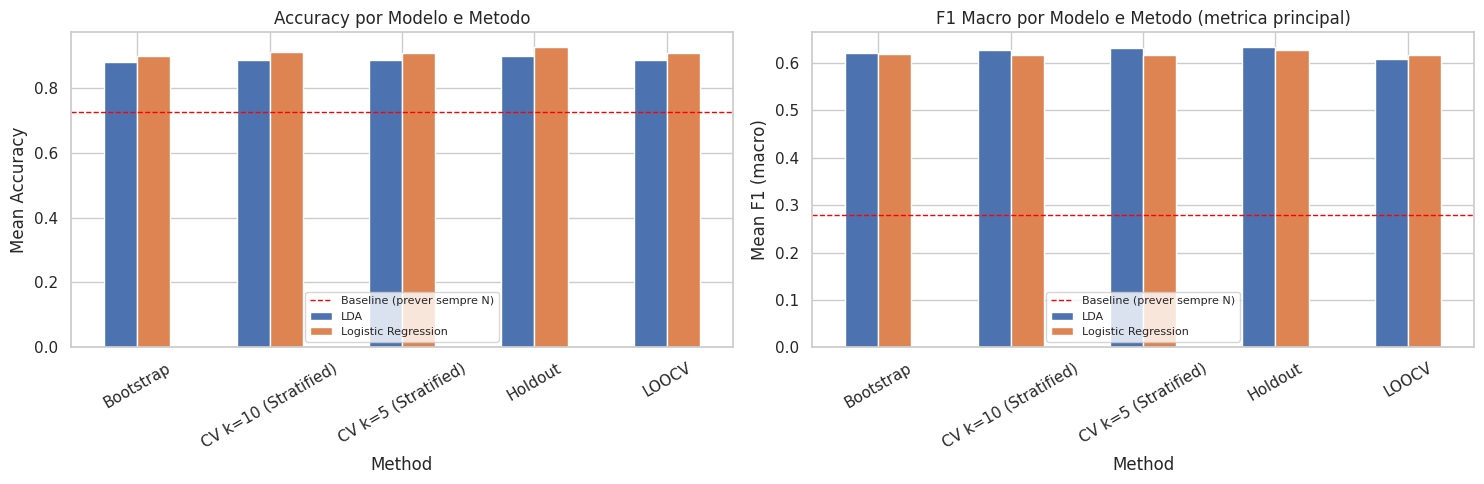

In [33]:
clf_results_df = pd.DataFrame(clf_results).sort_values(
    ['Model', 'Mean F1 (macro)'], ascending=[True, False]
)
display(clf_results_df[['Model', 'Method', 'Mean Accuracy', 'Acc Std',
                         'Mean F1 (macro)', 'F1 Std']])

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

pivot_acc = clf_results_df.pivot(index='Method', columns='Model', values='Mean Accuracy')
pivot_acc.plot(kind='bar', ax=axes[0])
axes[0].set_title('Accuracy por Modelo e Metodo')
axes[0].set_ylabel('Mean Accuracy')
axes[0].axhline(0.725, color='red', linestyle='--', linewidth=1,
                label='Baseline (prever sempre N)')
axes[0].legend(fontsize=8)
axes[0].tick_params(axis='x', rotation=30)

pivot_f1 = clf_results_df.pivot(index='Method', columns='Model', values='Mean F1 (macro)')
pivot_f1.plot(kind='bar', ax=axes[1])
axes[1].set_title('F1 Macro por Modelo e Metodo (metrica principal)')
axes[1].set_ylabel('Mean F1 (macro)')
axes[1].axhline(0.28, color='red', linestyle='--', linewidth=1,
                label='Baseline (prever sempre N)')
axes[1].legend(fontsize=8)
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()


### 4.6 Efeito dos métodos de reamostragem na variância

Para comparar a variância das estimativas, reunimos os desvios-padrão de cada método. Como o Holdout produz uma única estimativa (sem desvio-padrão), repetimo-lo com 30 partições aleatórias diferentes (seeds 0–29): a dispersão resultante mostra quanto a estimativa de um único Holdout depende da partição escolhida.

In [34]:
# Repeated holdout: how much does a single holdout estimate depend on the split?
N_REPEATS = 30
rep_rows = []
for name in clf_models:
    accs, f1s = [], []
    for seed in range(N_REPEATS):
        Xtr, Xte, ytr, yte = train_test_split(
            X_clf, y_class, test_size=0.2, stratify=y_class, random_state=seed)
        pipe = clf_pipe(name).fit(Xtr, ytr)
        y_pred = pipe.predict(Xte)
        accs.append(accuracy_score(yte, y_pred))
        f1s.append(f1_score(yte, y_pred, average='macro', zero_division=0))
    rep_rows.append({'Model': name, 'Method': f'Holdout repetido (x{N_REPEATS})',
                     'Acc Std': np.std(accs), 'F1 Std': np.std(f1s),
                     'Mean Accuracy': np.mean(accs), 'Mean F1 (macro)': np.mean(f1s)})
    print(f'{name} — Holdout x{N_REPEATS}: Acc={np.mean(accs):.4f}+-{np.std(accs):.4f}  '
          f'F1={np.mean(f1s):.4f}+-{np.std(f1s):.4f}  '
          f'(F1 min={np.min(f1s):.4f}, max={np.max(f1s):.4f})')

method_order = ['Holdout repetido (x30)', 'CV k=5 (Stratified)', 'CV k=10 (Stratified)', 'LOOCV', 'Bootstrap']
var_df = pd.concat([clf_results_df[clf_results_df['Method'] != 'Holdout'], pd.DataFrame(rep_rows)])
var_table = var_df.pivot(index='Method', columns='Model', values=['Acc Std', 'F1 Std']).reindex(method_order)
display(var_table.round(4))
print('Nota: no LOOCV o F1 é calculado globalmente (uma única estimativa), pelo que não tem desvio-padrão.')

Logistic Regression — Holdout x30: Acc=0.9075+-0.0073  F1=0.6189+-0.0188  (F1 min=0.5957, max=0.6568)
LDA — Holdout x30: Acc=0.8847+-0.0091  F1=0.6236+-0.0293  (F1 min=0.5741, max=0.6951)


Acc Std                      F1 Std                    
Model                      LDA Logistic Regression     LDA Logistic Regression
Method                                                                        
Holdout repetido (x30)  0.0091              0.0073  0.0293              0.0188
CV k=5 (Stratified)     0.0138              0.0081  0.0224              0.0088
CV k=10 (Stratified)    0.0155              0.0135  0.0483              0.0227
LOOCV                   0.3184              0.2883  0.0000              0.0000
Bootstrap               0.0114              0.0083  0.0276              0.0196

Nota: no LOOCV o F1 é calculado globalmente (uma única estimativa), pelo que não tem desvio-padrão.


#### Conclusões: variância por método de reamostragem

- **Holdout:** uma única partição dá uma única estimativa, sem medida de incerteza. A repetição com 30 seeds mostra que o F1 macro de um holdout varia de forma considerável consoante a partição: entre 0.596 e 0.657 na LR e entre 0.574 e 0.695 no LDA (std 0.019 e 0.029). Isto acontece sobretudo porque o conjunto de teste tem apenas 17 casos de HT, pelo que acertar ou falhar 1–2 casos muda bastante o F1 dessa classe. Como o resultado reportado de um holdout é um único valor, esta dispersão é toda ela incerteza da estimativa; nos métodos multi-partição, a média de várias iterações reduz essa incerteza.
- **CV k=5 vs k=10:** a média praticamente não muda entre k=5 e k=10, mas o desvio-padrão entre folds (variância de cada fold, não da média final) aumenta com k=10 (LR: F1 Std 0.009 → 0.023; LDA: 0.022 → 0.048). Com k=10, cada fold de teste tem só ~200 amostras e ~8 casos de HT, o que torna o score de cada fold mais instável. Em contrapartida, cada modelo treina com 90% dos dados (menor viés).
- **LOOCV:** treina com n-1 instâncias, logo o viés é praticamente nulo. O desvio-padrão por fold (~0.29-0.32) não é comparável aos outros métodos, porque cada fold tem uma única amostra e o score é 0 ou 1 (std = √(p·(1-p))). Os n modelos são quase idênticos entre si, pelo que os erros estão fortemente correlacionados: é o método mais caro e o que tem, teoricamente, maior variância como estimador.
- **Bootstrap:** a média é a mais baixa de todos os métodos (estimativa mais conservadora/pessimista), porque cada modelo treina apenas com ~63.2% de instâncias únicas. O desvio-padrão entre iterações (F1 Std ≈ 0.020–0.028) é da mesma ordem que o do CV k=5/k=10.

**Em resumo:** todos os métodos multi-partição (CV, LOOCV, Bootstrap) chegam a médias muito próximas, o que dá confiança nas estimativas. A variância depende sobretudo do tamanho do conjunto de avaliação de cada iteração, e a classe HT (4.1%) amplifica essa variância. O **CV estratificado com k=5** oferece o melhor compromisso entre viés, variância e custo computacional neste dataset.

### 4.7 Discussão e escolha do modelo

#### Porque é que a accuracy é enganosa neste dataset

Com a distribuição de classes N=72.5%, DI=23.4%, HT=4.1%, um classificador que preveja sempre **N** obtém:

- **Accuracy: 72.5%** — parece razoável
- **F1 macro: ~0.28** — revela que o modelo não aprende nada

O F1 macro calcula o F1 por classe e faz a média aritmética, penalizando igualmente os erros em todas as classes. É, por isso, o critério de decisão principal neste capítulo.

---

#### Análise dos resultados

**Accuracy vs F1 macro: a diferença revela o problema**

Os valores de accuracy (~88-92%) são consistentemente elevados em todos os métodos e modelos. No entanto, o F1 macro (~0.61-0.63) é substancialmente mais baixo, o que confirma que os modelos capturam bem N e DI (F1 ≈ 0.88-0.95 no Holdout), mas falham quase por completo em HT. A matriz de confusão do Holdout mostra isto diretamente: o recall de HT é 0.00 na LR e 0.06 no LDA (1 em 17 casos).

**Logistic Regression vs LDA**

| Método | LR Accuracy | LDA Accuracy | LR F1 macro | LDA F1 macro |
|---|---|---|---|---|
| Holdout | **0.9250** | 0.8975 | 0.6283 | **0.6332** |
| CV k=5 | **0.9080** | 0.8865 | 0.6160 | **0.6320** |
| CV k=10 | **0.9095** | 0.8865 | 0.6167 | **0.6279** |
| LOOCV | **0.9085** | 0.8855 | **0.6172** | 0.6092 |
| Bootstrap | **0.8998** | 0.8784 | 0.6188 | **0.6219** |

Os dois modelos têm comportamentos opostos:
- A **LR** tem accuracy mais alta em todos os métodos (~+2 p.p.) e menor desvio-padrão, mas nunca acerta em HT: maximiza o desempenho nas classes frequentes.
- O **LDA** tem F1 macro ligeiramente superior em 4 dos 5 métodos, porque consegue identificar alguns casos de HT, à custa de mais erros em DI (recall de DI: 0.84 vs 0.94 na LR).

As diferenças de F1 macro são pequenas (~0.01), da ordem do desvio-padrão entre folds, pelo que nenhum dos modelos é claramente superior. É de notar que o LDA tem desempenho competitivo apesar de os seus pressupostos (distribuições gaussianas com covariâncias iguais entre classes) serem violados pelas distribuições bimodais e pelos picos de imputação observados na EDA.

**Modelo escolhido: LDA.** Seguindo o critério definido no início do capítulo (F1 macro), o LDA é o modelo mais apropriado: é superior em 4 dos 5 métodos de reamostragem e é o único que deteta alguma fração da classe minoritária HT, que é clinicamente a mais relevante de não ignorar. Se o objetivo fosse maximizar a taxa global de acertos, a LR seria preferível.

---

#### Conclusão

Ambos os modelos lineares são limitados pelo desequilíbrio de classes e pela fraca separabilidade linear da classe HT, que não tem associação relevante com nenhuma feature numérica (confirmada na EDA). Para melhorar o F1 macro nas classes minoritárias, os próximos passos seriam: técnicas de rebalanceamento (SMOTE, `class_weight='balanced'`), ajuste do threshold de decisão ou modelos não lineares.

#### Concordância com a EDA

Os resultados da classificação estão em linha com as previsões da EDA:

| Previsão da EDA | Resultado observado | Concordância |
|---|---|---|
| Desequilíbrio N=72.5% / DI=23.4% / HT=4.1% → accuracy enganosa | Accuracy ~89–92% mas F1 macro substancialmente menor; recall de HT ≈ 0 no Holdout | ✓ Confirmada |
| `age` e `HbA1c_level` melhores discriminadores visuais (boxplots) | `HbA1c_level` é a feature com maior coeficiente na LR regularizada e `age` está no top-3 (secção 5) | ✓ Confirmada |
| Distribuições bimodais e imputação massiva violam os pressupostos do LDA → esperar pior desempenho do LDA | O LDA tem accuracy ~2 p.p. inferior, mas F1 macro igual ou ligeiramente superior (deteta alguns casos de HT) | ✗ Parcialmente refutada |
| `triglycerides` tem padrão contraintuitivo (N com mediana > DI) | `triglycerides` está entre as features com maior coeficiente na LR regularizada (secção 5): é informativa, mesmo com o sinal contraintuitivo | ✓ Confirmada |

**Nota sobre HT:** a EDA avisou para a severidade desta classe minoritária (4.1%). O recall de HT de 0.00 (LR) e 0.06 (LDA) confirma que os modelos lineares sem rebalanceamento não conseguem capturar este subgrupo, o que justifica as sugestões de SMOTE ou `class_weight='balanced'` para trabalho futuro.

---
## 5. Feature Selection: Ridge, Lasso & Elastic Net

Avaliamos o impacto da seleção de features no desempenho da classificação, através de regularização aplicada à Regressão Logística:

- **Ridge (L2):** encolhe os coeficientes sem os anular; serve para ordenar as features por importância.
- **Lasso (L1):** anula coeficientes e faz seleção automática.
- **Elastic Net (L1 + L2):** combina os dois comportamentos (complemento aos dois métodos pedidos).

**Protocolo (sem data leakage):**
1. A seleção de features e a escolha da força de regularização (`C`) são feitas **apenas no conjunto de treino** do Holdout (80%), com `StratifiedKFold` k=5 e **F1 macro** como métrica.
2. Cada conjunto de features é avaliado com **LR e LDA**: (a) por CV estratificada k=5 no treino e (b) no **conjunto de teste** do Holdout, que nunca é usado na seleção.
3. Métrica principal: **F1 macro** (coerente com a secção 4); a accuracy é reportada para referência.

Definimos a estratégia de validação, a grelha de valores de `C` (inverso da força de regularização: `C` pequeno significa regularização forte) e uma função que avalia um conjunto de features com os dois classificadores.

In [35]:
import warnings
from sklearn.linear_model import LogisticRegressionCV
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', message='.*l1_ratio.*')   # penalty/l1_ratio compatibility notices

fs_cv   = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
Cs_grid = np.logspace(-3, 2, 20)
fs_comparison = []

def evaluate_features(feat_list, label):
    # Evaluates a feature subset with LR and LDA: stratified 5-fold CV on train + holdout test
    idx = [FEATURES.index(f) for f in feat_list]
    Xtr, Xte = X_train_c[:, idx], X_test_c[:, idx]
    for mname in clf_models:
        pipe   = clf_pipe(mname)
        f1_cv  = cross_val_score(pipe, Xtr, y_train_c, cv=fs_cv, scoring='f1_macro')
        acc_cv = cross_val_score(pipe, Xtr, y_train_c, cv=fs_cv, scoring='accuracy')
        y_pred = pipe.fit(Xtr, y_train_c).predict(Xte)
        row = {'Feature Set': label, 'Model': mname, 'n_features': len(idx),
               'F1 CV (treino)': f1_cv.mean(), 'F1 CV Std': f1_cv.std(),
               'Acc CV (treino)': acc_cv.mean(),
               'F1 Teste': f1_score(y_test_c, y_pred, average='macro', zero_division=0),
               'Acc Teste': accuracy_score(y_test_c, y_pred)}
        fs_comparison.append(row)
        print(f"{label:<24} | {mname:<19} | n={len(idx):>2} | "
              f"F1 CV={row['F1 CV (treino)']:.4f}+-{row['F1 CV Std']:.4f} | "
              f"F1 teste={row['F1 Teste']:.4f} | Acc teste={row['Acc Teste']:.4f}")

def fit_regularized(penalty, l1_ratio=None):
    # Chooses C by stratified CV (F1 macro) on the training set.
    # Returns the CV object, the best C and the 1-SE C (strongest regularization
    # whose mean CV F1 is within one standard error of the best).
    # l1_ratio is passed explicitly so the penalty is the same in old and new
    # scikit-learn versions (>=1.8 uses l1_ratio instead of penalty)
    ratio = {'l2': 0.0, 'l1': 1.0}.get(penalty, l1_ratio)
    kw = dict(Cs=Cs_grid, cv=fs_cv, penalty=penalty, l1_ratios=[ratio],
              scoring='f1_macro', max_iter=10000, random_state=RANDOM_STATE)
    if penalty in ('l1', 'elasticnet'):
        kw['solver'] = 'saga'
    cv_model = LogisticRegressionCV(**kw).fit(X_train_c_sc, y_train_c)
    scores = np.asarray(list(cv_model.scores_.values())[0]).reshape(fs_cv.get_n_splits(), -1)
    mean, se = scores.mean(axis=0), scores.std(axis=0) / np.sqrt(scores.shape[0])
    best = mean.argmax()
    c_best = cv_model.Cs_[best]
    c_1se  = cv_model.Cs_[np.where(mean >= mean[best] - se[best])[0].min()]
    return cv_model, c_best, c_1se, mean

def importance_table(coef):
    return pd.DataFrame({'Feature': feature_names,
                         'Coefficient': np.abs(coef).mean(axis=0)}
                        ).sort_values('Coefficient', ascending=False)

### 5.1 Baseline: All Features

Baseline com todas as 40 features: referência para medir o impacto de cada método de seleção. Reduzir features sem degradar o desempenho indica que as features removidas eram redundantes ou ruidosas.

In [36]:
evaluate_features(FEATURES, 'All Features')

All Features             | Logistic Regression | n=40 | F1 CV=0.6344+-0.0480 | F1 teste=0.6283 | Acc teste=0.9250
All Features             | LDA                 | n=40 | F1 CV=0.6213+-0.0499 | F1 teste=0.6332 | Acc teste=0.8975


### 5.2 Ridge (L2): Feature Importance

**Ridge (L2)** adiciona uma penalização $\lambda \sum_j \beta_j^2$ que encolhe todos os coeficientes em direção a zero sem os anular. Escolhemos `C` por CV no treino e, como as features estão normalizadas, usamos a média dos |coeficientes| entre as três classes como medida de importância. Como o Ridge não elimina features, o tamanho do conjunto reduzido (top-N) é escolhido também por CV no treino, com a **regra de um erro-padrão**: o menor N cujo F1 médio fica a menos de um erro-padrão do melhor (preferimos o modelo mais simples entre os estatisticamente equivalentes).

Ridge — melhor C por CV (F1 macro): 1.438


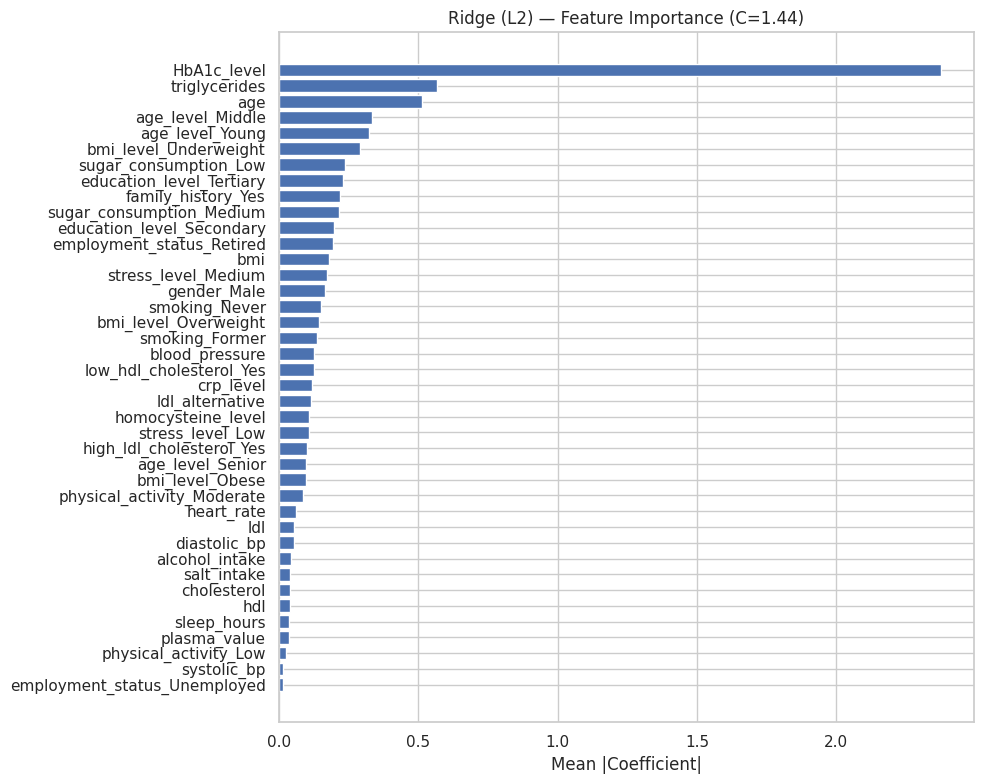

                 Feature  Coefficient
             HbA1c_level     2.374977
           triglycerides     0.568098
                     age     0.513571
        age_level_Middle     0.334012
         age_level_Young     0.324390
   bmi_level_Underweight     0.288654
   sugar_consumption_Low     0.237821
education_level_Tertiary     0.228710
      family_history_Yes     0.219767
sugar_consumption_Medium     0.213607


In [37]:
ridge_cv, ridge_c_best, _, _ = fit_regularized('l2')
print(f'Ridge — melhor C por CV (F1 macro): {ridge_c_best:.4g}')

ridge_importance = importance_table(ridge_cv.coef_)

plt.figure(figsize=(10, 8))
plt.barh(ridge_importance['Feature'][::-1], ridge_importance['Coefficient'][::-1])
plt.xlabel('Mean |Coefficient|')
plt.title(f'Ridge (L2) — Feature Importance (C={ridge_c_best:.3g})')
plt.tight_layout()
plt.show()
print(ridge_importance.head(10).to_string(index=False))

Melhor N (F1 CV máximo): 39 -> F1=0.6356
N escolhido (regra 1-SE): 19 -> F1=0.6161
Features: ['HbA1c_level', 'triglycerides', 'age', 'age_level_Middle', 'age_level_Young', 'bmi_level_Underweight', 'sugar_consumption_Low', 'education_level_Tertiary', 'family_history_Yes', 'sugar_consumption_Medium', 'education_level_Secondary', 'employment_status_Retired', 'bmi', 'stress_level_Medium', 'gender_Male', 'smoking_Never', 'bmi_level_Overweight', 'smoking_Former', 'blood_pressure']


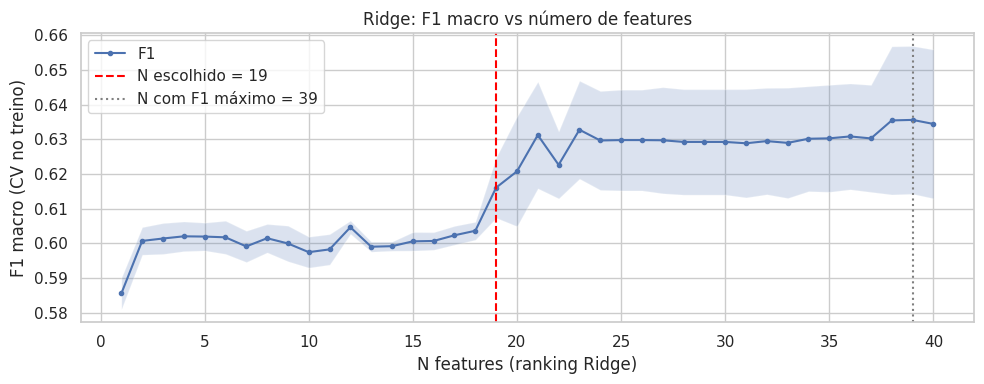

In [38]:
# Choose the size of the Ridge top-N subset by CV on the training set (1-SE rule)
ranked = ridge_importance['Feature'].tolist()
topn_rows = []
for n in range(1, len(ranked) + 1):
    idx = [FEATURES.index(f) for f in ranked[:n]]
    s = cross_val_score(clf_pipe('Logistic Regression'), X_train_c[:, idx], y_train_c,
                        cv=fs_cv, scoring='f1_macro')
    topn_rows.append({'N': n, 'F1': s.mean(), 'SE': s.std() / np.sqrt(len(s))})
ridge_topn_df = pd.DataFrame(topn_rows).set_index('N')

best_n = ridge_topn_df['F1'].idxmax()
thr = ridge_topn_df.loc[best_n, 'F1'] - ridge_topn_df.loc[best_n, 'SE']
TOP_N_RIDGE = int(ridge_topn_df[ridge_topn_df['F1'] >= thr].index.min())
ridge_top_feats = ranked[:TOP_N_RIDGE]
print(f'Melhor N (F1 CV máximo): {best_n} -> F1={ridge_topn_df.loc[best_n, "F1"]:.4f}')
print(f'N escolhido (regra 1-SE): {TOP_N_RIDGE} -> F1={ridge_topn_df.loc[TOP_N_RIDGE, "F1"]:.4f}')
print('Features:', ridge_top_feats)

ax = ridge_topn_df['F1'].plot(marker='o', markersize=3, figsize=(10, 4))
ax.fill_between(ridge_topn_df.index, ridge_topn_df['F1'] - ridge_topn_df['SE'],
                ridge_topn_df['F1'] + ridge_topn_df['SE'], alpha=0.2)
ax.axvline(TOP_N_RIDGE, color='red', linestyle='--', label=f'N escolhido = {TOP_N_RIDGE}')
ax.axvline(best_n, color='grey', linestyle=':', label=f'N com F1 máximo = {best_n}')
ax.set_xlabel('N features (ranking Ridge)'); ax.set_ylabel('F1 macro (CV no treino)')
ax.set_title('Ridge: F1 macro vs número de features'); ax.legend()
plt.tight_layout(); plt.show()

In [39]:
evaluate_features(ridge_top_feats, f'Ridge Top {TOP_N_RIDGE}')

Ridge Top 19             | Logistic Regression | n=19 | F1 CV=0.6161+-0.0195 | F1 teste=0.6303 | Acc teste=0.9325
Ridge Top 19             | LDA                 | n=19 | F1 CV=0.5989+-0.0135 | F1 teste=0.6073 | Acc teste=0.9100


### 5.3 Lasso (L1): Feature Selection

**Lasso (L1)** adiciona uma penalização $\lambda \sum_j |\beta_j|$ que produz soluções esparsas: os coeficientes das features irrelevantes ficam exatamente a zero, o que faz uma seleção implícita. Usamos o solver `saga`, que suporta L1 em problemas multiclasse (multinomial). Escolhemos `C` por CV no treino com a **regra de um erro-padrão** (o `C` mais pequeno, ou seja, a regularização mais forte, cujo F1 está a menos de um erro-padrão do melhor). Uma feature é selecionada se tiver coeficiente não nulo em pelo menos uma das três classes. Mostramos também o caminho de regularização (número de features não nulas e F1 em CV para cada `C`).

Lasso — melhor C: 1.438 | C escolhido (1-SE): 1.438



Lasso selecionou 40 features: ['HbA1c_level', 'triglycerides', 'age', 'bmi_level_Underweight', 'age_level_Middle', 'education_level_Tertiary', 'family_history_Yes', 'employment_status_Retired', 'sugar_consumption_Medium', 'age_level_Young', 'education_level_Secondary', 'sugar_consumption_Low', 'gender_Male', 'stress_level_Medium', 'blood_pressure', 'smoking_Former', 'bmi', 'low_hdl_cholesterol_Yes', 'smoking_Never', 'bmi_level_Overweight', 'crp_level', 'homocysteine_level', 'ldl_alternative', 'stress_level_Low', 'high_ldl_cholesterol_Yes', 'physical_activity_Moderate', 'heart_rate', 'diastolic_bp', 'ldl', 'alcohol_intake', 'cholesterol', 'age_level_Senior', 'hdl', 'plasma_value', 'sleep_hours', 'bmi_level_Obese', 'salt_intake', 'physical_activity_Low', 'systolic_bp', 'employment_status_Unemployed']

Lasso eliminou 0 features: []


,C,N features,F1 macro (CV)
0,0.0010,0,0.2802
1,0.0018,0,0.2802
2,0.0034,1,0.2802
3,0.0062,1,0.3516
4,0.0113,3,0.6088
5,0.0207,5,0.6011
6,0.0379,13,0.6029
7,0.0695,21,0.6048
8,0.1274,29,0.6065
9,0.2336,34,0.6123


Lasso esparso: C=0.01129 | F1 CV=0.6088 (máximo=0.6455) | 3 features: ['age', 'HbA1c_level', 'triglycerides']


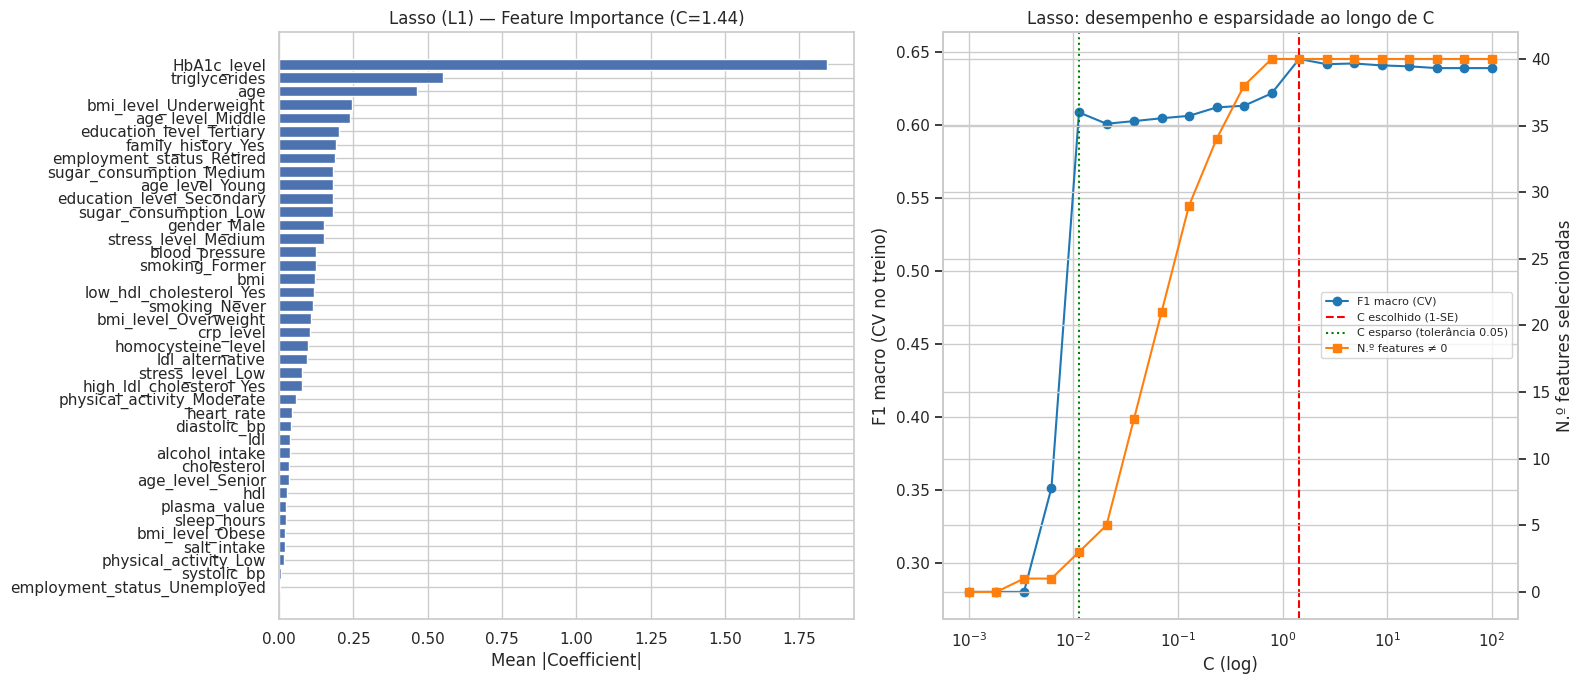

In [40]:
lasso_cv, lasso_c_best, lasso_c_1se, lasso_mean = fit_regularized('l1')
print(f'Lasso — melhor C: {lasso_c_best:.4g} | C escolhido (1-SE): {lasso_c_1se:.4g}')

lasso_clf = LogisticRegression(penalty='l1', l1_ratio=1.0, solver='saga', C=lasso_c_1se,
                               max_iter=10000, random_state=RANDOM_STATE)
lasso_clf.fit(X_train_c_sc, y_train_c)

lasso_importance = importance_table(lasso_clf.coef_)
lasso_mask = np.any(np.abs(lasso_clf.coef_) > 1e-8, axis=0)
lasso_selected = [f for f in lasso_importance['Feature'] if lasso_mask[FEATURES.index(f)]]
lasso_removed  = [f for f in FEATURES if f not in lasso_selected]
print(f'\nLasso selecionou {len(lasso_selected)} features: {lasso_selected}')
print(f'\nLasso eliminou {len(lasso_removed)} features: {lasso_removed}')

# Regularization path: number of non-zero features for each C
n_nonzero, supports = [], []
for C in Cs_grid:
    m = LogisticRegression(penalty='l1', l1_ratio=1.0, solver='saga', C=C, max_iter=10000,
                           random_state=RANDOM_STATE).fit(X_train_c_sc, y_train_c)
    nz = np.any(np.abs(m.coef_) > 1e-8, axis=0)
    n_nonzero.append(int(nz.sum()))
    supports.append([f for f, keep in zip(FEATURES, nz) if keep])
lasso_path_df = pd.DataFrame({'C': Cs_grid, 'N features': n_nonzero, 'F1 macro (CV)': lasso_mean})
display(lasso_path_df.round(4))

# Sparse operating point: strongest regularization whose CV F1 is within 0.05 of the best
TOL = 0.05
ok = np.where((lasso_mean >= lasso_mean.max() - TOL) & (np.array(n_nonzero) > 0))[0]
i_sparse = ok.min()
lasso_c_sparse = Cs_grid[i_sparse]
lasso_sparse_feats = supports[i_sparse]
print(f'Lasso esparso: C={lasso_c_sparse:.4g} | F1 CV={lasso_mean[i_sparse]:.4f} '
      f'(máximo={lasso_mean.max():.4f}) | {len(lasso_sparse_feats)} features: {lasso_sparse_feats}')

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
axes[0].barh(lasso_importance['Feature'][::-1], lasso_importance['Coefficient'][::-1])
axes[0].set_xlabel('Mean |Coefficient|')
axes[0].set_title(f'Lasso (L1) — Feature Importance (C={lasso_c_1se:.3g})')
ax2 = axes[1]; ax3 = ax2.twinx()
ax2.semilogx(Cs_grid, lasso_mean, marker='o', color='tab:blue', label='F1 macro (CV)')
ax3.semilogx(Cs_grid, n_nonzero, marker='s', color='tab:orange', label='N.º features ≠ 0')
ax2.axvline(lasso_c_1se, color='red', linestyle='--', label='C escolhido (1-SE)')
ax2.axvline(lasso_c_sparse, color='green', linestyle=':', label='C esparso (tolerância 0.05)')
ax2.set_xlabel('C (log)'); ax2.set_ylabel('F1 macro (CV no treino)'); ax3.set_ylabel('N.º features selecionadas')
ax2.set_title('Lasso: desempenho e esparsidade ao longo de C')
h1, l1 = ax2.get_legend_handles_labels(); h2, l2 = ax3.get_legend_handles_labels()
ax2.legend(h1 + h2, l1 + l2, loc='center right', fontsize=8)
plt.tight_layout(); plt.show()

In [41]:
evaluate_features(lasso_selected, f'Lasso CV ({len(lasso_selected)})')

Lasso CV (40)            | Logistic Regression | n=40 | F1 CV=0.6344+-0.0480 | F1 teste=0.6283 | Acc teste=0.9250
Lasso CV (40)            | LDA                 | n=40 | F1 CV=0.6213+-0.0499 | F1 teste=0.6332 | Acc teste=0.8975


Para avaliar um conjunto realmente reduzido, usamos também o **ponto esparso** do caminho de regularização: a regularização mais forte cujo F1 macro em CV (no treino) fica a menos de 0.05 do melhor valor do caminho. Trocamos uma perda pequena e controlada de F1 por um modelo muito mais simples.

In [42]:
evaluate_features(lasso_sparse_feats, f'Lasso esparso ({len(lasso_sparse_feats)})')

Lasso esparso (3)        | Logistic Regression | n= 3 | F1 CV=0.6014+-0.0099 | F1 teste=0.6185 | Acc teste=0.9175
Lasso esparso (3)        | LDA                 | n= 3 | F1 CV=0.5887+-0.0064 | F1 teste=0.6073 | Acc teste=0.9075


### 5.4 Elastic Net (L1 + L2): Feature Selection

**Elastic Net** combina L1 e L2: a componente L1 induz esparsidade e a componente L2 estabiliza os coeficientes quando features correlacionadas competem entre si. Com `l1_ratio=0.5`, o peso é distribuído igualmente pelas duas penalizações. O `C` é escolhido com o mesmo protocolo do Lasso (CV no treino + regra 1-SE).

Elastic Net — melhor C: 1.438 | C escolhido (1-SE): 0.4281



Elastic Net selecionou 40 features: ['HbA1c_level', 'triglycerides', 'age', 'bmi_level_Underweight', 'family_history_Yes', 'age_level_Middle', 'education_level_Tertiary', 'sugar_consumption_Low', 'employment_status_Retired', 'gender_Male', 'sugar_consumption_Medium', 'education_level_Secondary', 'stress_level_Medium', 'blood_pressure', 'low_hdl_cholesterol_Yes', 'smoking_Never', 'bmi_level_Overweight', 'smoking_Former', 'bmi', 'age_level_Young', 'crp_level', 'homocysteine_level', 'ldl_alternative', 'high_ldl_cholesterol_Yes', 'stress_level_Low', 'physical_activity_Moderate', 'age_level_Senior', 'diastolic_bp', 'ldl', 'cholesterol', 'alcohol_intake', 'heart_rate', 'bmi_level_Obese', 'plasma_value', 'sleep_hours', 'hdl', 'salt_intake', 'employment_status_Unemployed', 'systolic_bp', 'physical_activity_Low']

Elastic Net eliminou: []


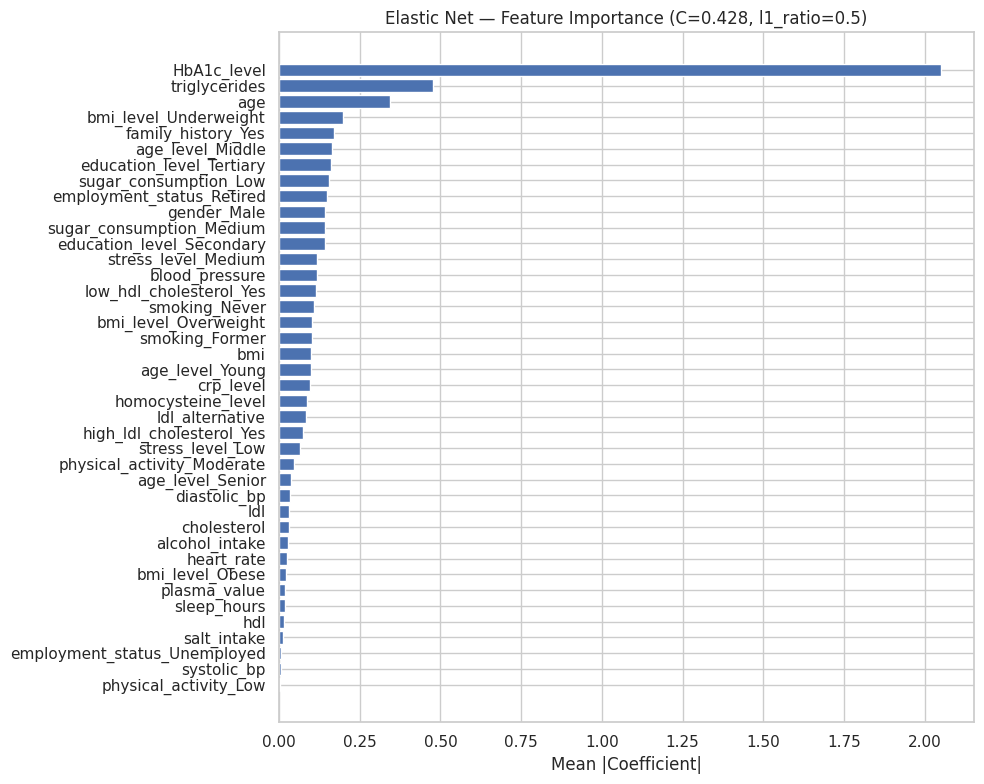

In [43]:
enet_cv, enet_c_best, enet_c_1se, _ = fit_regularized('elasticnet', l1_ratio=0.5)
print(f'Elastic Net — melhor C: {enet_c_best:.4g} | C escolhido (1-SE): {enet_c_1se:.4g}')

enet_clf = LogisticRegression(penalty='elasticnet', solver='saga', l1_ratio=0.5, C=enet_c_1se,
                              max_iter=10000, random_state=RANDOM_STATE)
enet_clf.fit(X_train_c_sc, y_train_c)

enet_importance = importance_table(enet_clf.coef_)
enet_mask = np.any(np.abs(enet_clf.coef_) > 1e-8, axis=0)
enet_selected = [f for f in enet_importance['Feature'] if enet_mask[FEATURES.index(f)]]
print(f'\nElastic Net selecionou {len(enet_selected)} features: {enet_selected}')
print(f'\nElastic Net eliminou: {[f for f in FEATURES if f not in enet_selected]}')

plt.figure(figsize=(10, 8))
plt.barh(enet_importance['Feature'][::-1], enet_importance['Coefficient'][::-1])
plt.xlabel('Mean |Coefficient|')
plt.title(f'Elastic Net — Feature Importance (C={enet_c_1se:.3g}, l1_ratio=0.5)')
plt.tight_layout()
plt.show()

In [44]:
evaluate_features(enet_selected, f'Elastic Net ({len(enet_selected)})')

Elastic Net (40)         | Logistic Regression | n=40 | F1 CV=0.6344+-0.0480 | F1 teste=0.6283 | Acc teste=0.9250
Elastic Net (40)         | LDA                 | n=40 | F1 CV=0.6213+-0.0499 | F1 teste=0.6332 | Acc teste=0.8975


### 5.5 Comparison

Comparamos os conjuntos de features em duas dimensões, desempenho (F1 macro) e número de features, porque o objetivo é o melhor compromisso entre desempenho e simplicidade: um modelo mais parcimonioso com o mesmo desempenho é preferível (mais interpretável, menor risco de overfitting).

,Feature Set,Model,n_features,F1 CV (treino),F1 CV Std,Acc CV (treino),F1 Teste,Acc Teste
0,All Features,Logistic Regression,40,0.6344,0.0480,0.9019,0.6283,0.9250
1,All Features,LDA,40,0.6213,0.0499,0.8731,0.6332,0.8975
2,Ridge Top 19,Logistic Regression,19,0.6161,0.0195,0.9062,0.6303,0.9325
3,Ridge Top 19,LDA,19,0.5989,0.0135,0.8906,0.6073,0.9100
4,Lasso CV (40),Logistic Regression,40,0.6344,0.0480,0.9019,0.6283,0.9250
5,Lasso CV (40),LDA,40,0.6213,0.0499,0.8731,0.6332,0.8975
6,Lasso esparso (3),Logistic Regression,3,0.6014,0.0099,0.9019,0.6185,0.9175
7,Lasso esparso (3),LDA,3,0.5887,0.0064,0.8906,0.6073,0.9075
8,Elastic Net (40),Logistic Regression,40,0.6344,0.0480,0.9019,0.6283,0.9250
9,Elastic Net (40),LDA,40,0.6213,0.0499,0.8731,0.6332,0.8975


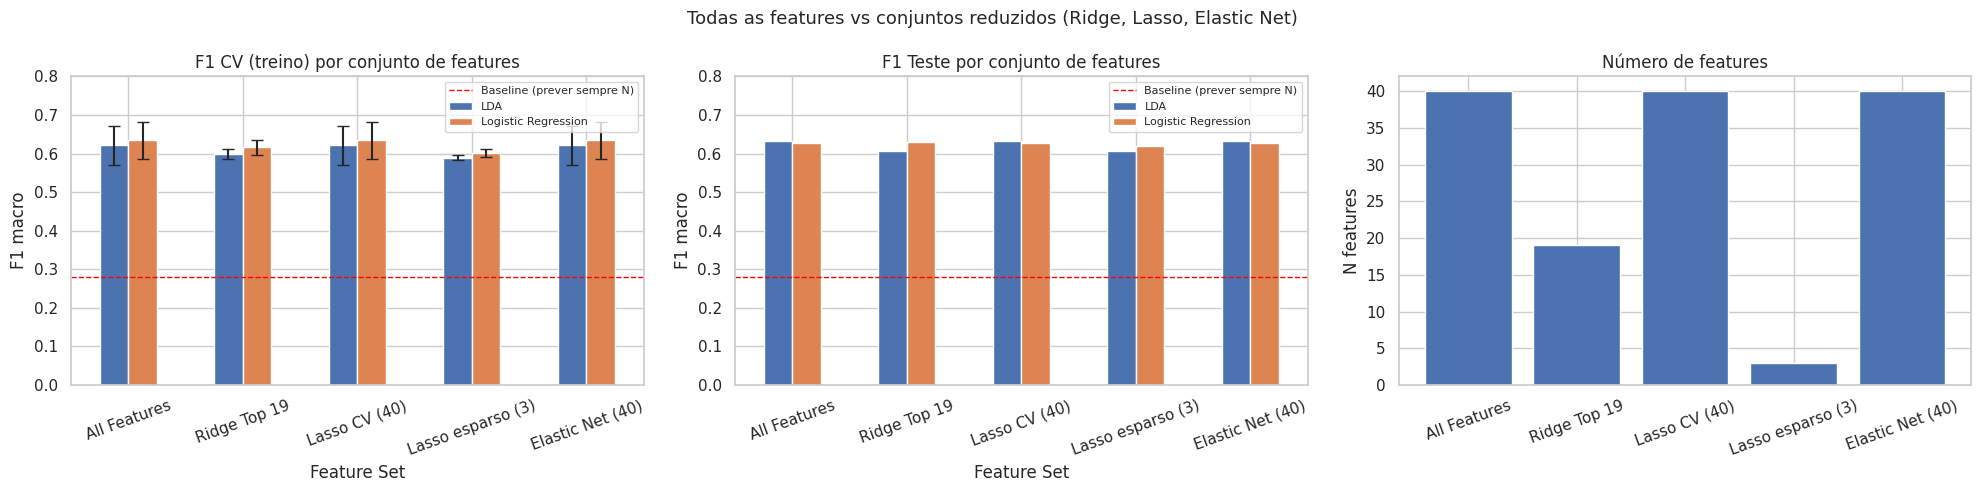

In [45]:
fs_comp_df = pd.DataFrame(fs_comparison)
display(fs_comp_df.round(4))

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, metric, err in zip(axes[:2], ['F1 CV (treino)', 'F1 Teste'], ['F1 CV Std', None]):
    piv = fs_comp_df.pivot(index='Feature Set', columns='Model', values=metric)
    piv = piv.reindex(fs_comp_df['Feature Set'].unique())
    yerr = fs_comp_df.pivot(index='Feature Set', columns='Model', values=err).reindex(piv.index) if err else None
    piv.plot(kind='bar', ax=ax, yerr=yerr, capsize=4)
    ax.axhline(0.28, color='red', linestyle='--', linewidth=1, label='Baseline (prever sempre N)')
    ax.set_title(f'{metric} por conjunto de features'); ax.set_ylabel('F1 macro')
    ax.set_ylim(0, 0.8); ax.tick_params(axis='x', rotation=20); ax.legend(fontsize=8)
n_feats = fs_comp_df.drop_duplicates('Feature Set')
axes[2].bar(n_feats['Feature Set'], n_feats['n_features'])
axes[2].set_title('Número de features'); axes[2].set_ylabel('N features')
axes[2].tick_params(axis='x', rotation=20)
plt.suptitle('Todas as features vs conjuntos reduzidos (Ridge, Lasso, Elastic Net)', fontsize=13)
plt.tight_layout()
plt.show()

### 5.6 Multicolinearidade (VIF)

O **VIF** (*Variance Inflation Factor*) mede a multicolinearidade residual nas features numéricas selecionadas. A regularização reduz os coeficientes, mas não elimina necessariamente a redundância entre features. Limiares: VIF > 10 indica multicolinearidade problemática; VIF entre 5 e 10 é moderada; VIF < 5 é aceitável.

Nota: a função `variance_inflation_factor` do statsmodels não adiciona intercept. Sem constante, as features com média alta e desvio-padrão baixo (como `blood_pressure`) têm VIF artificialmente enorme, por isso adicionamos a constante com `sm.add_constant` antes do cálculo.

In [46]:
import statsmodels.api as sm

def compute_vif(selected_feats, label):
    # Only numerical features are meaningful for VIF
    num_cols = [c for c in df_clean.select_dtypes(include=[np.number]).columns
                if c != 'target_regression' and c in selected_feats]
    if len(num_cols) < 2:
        print(f'{label}: menos de 2 features numéricas — VIF não aplicável')
        return None
    X_vif = sm.add_constant(df_clean[num_cols]).values   # intercept is required
    vif_vals = [variance_inflation_factor(X_vif, i) for i in range(1, X_vif.shape[1])]
    vif_df = pd.DataFrame({'Feature': num_cols, 'VIF': vif_vals}).sort_values('VIF', ascending=False)
    print(f'\n=== VIF — {label} ===')
    print(vif_df.to_string(index=False))
    return vif_df

vif_all   = compute_vif(FEATURES, 'All Features')
vif_ridge = compute_vif(ridge_top_feats, f'Ridge Top {TOP_N_RIDGE}')
vif_lasso = compute_vif(lasso_selected, f'Lasso ({len(lasso_selected)})')
vif_enet  = compute_vif(enet_selected,  f'Elastic Net ({len(enet_selected)})')


=== VIF — All Features ===
           Feature      VIF
               age 1.167368
     triglycerides 1.120854
    blood_pressure 1.103625
       HbA1c_level 1.065004
               bmi 1.060792
       cholesterol 1.037875
homocysteine_level 1.032036
       sleep_hours 1.030673
      diastolic_bp 1.024185
        heart_rate 1.020443
    alcohol_intake 1.017669
         crp_level 1.017620
       salt_intake 1.011930
       systolic_bp 1.011915
               ldl 1.009457
      plasma_value 1.008777
               hdl 1.007426
   ldl_alternative 1.007009

=== VIF — Ridge Top 19 ===
       Feature      VIF
           age 1.147138
 triglycerides 1.107910
blood_pressure 1.081940
   HbA1c_level 1.057452
           bmi 1.038037

=== VIF — Lasso (40) ===
           Feature      VIF
               age 1.167368
     triglycerides 1.120854
    blood_pressure 1.103625
       HbA1c_level 1.065004
               bmi 1.060792
       cholesterol 1.037875
homocysteine_level 1.032036
       sleep_hours

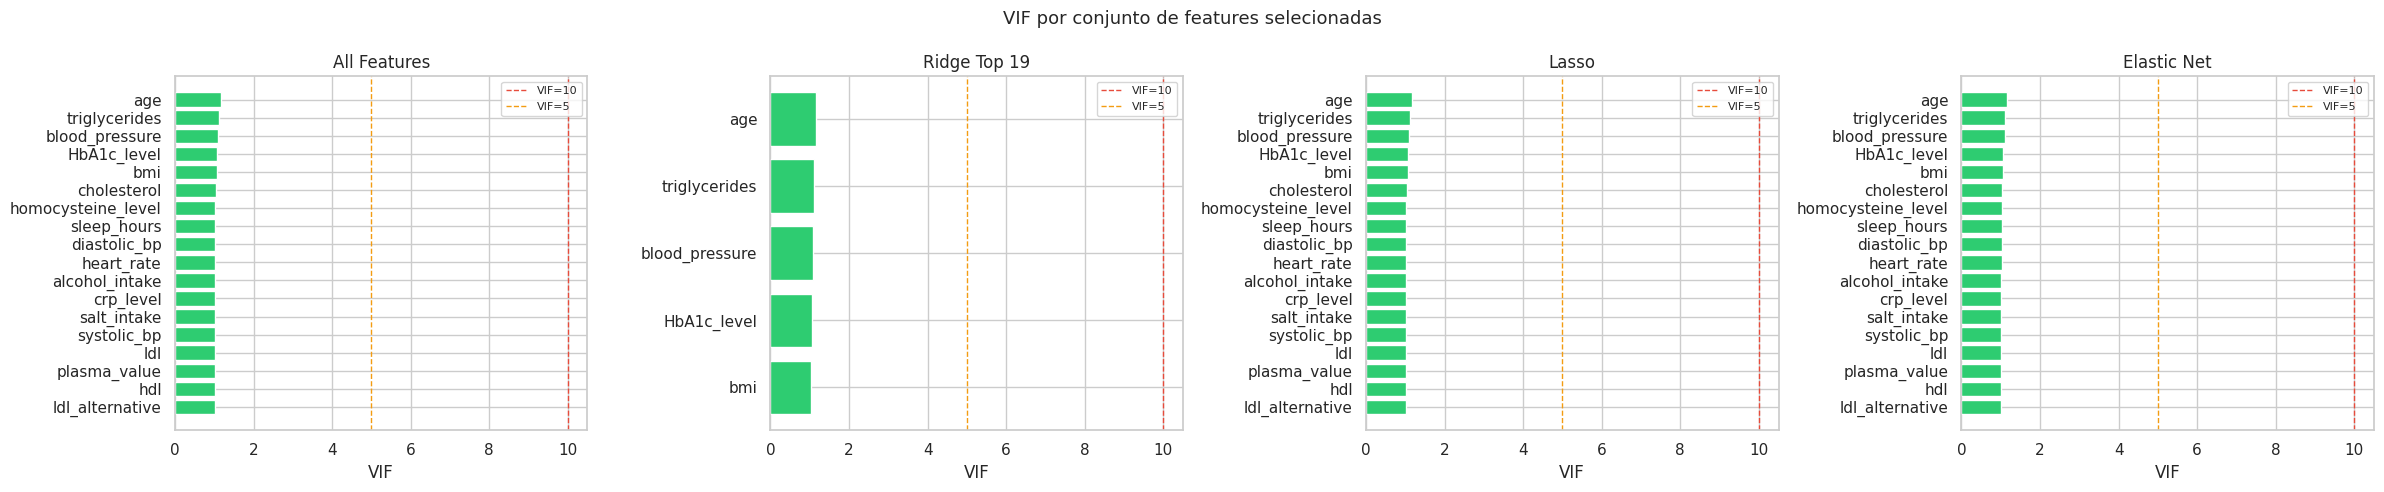

In [47]:
# VIF bar chart comparison across methods
vif_results = [
    (vif_all,   'All Features'),
    (vif_ridge, f'Ridge Top {TOP_N_RIDGE}'),
    (vif_lasso, 'Lasso'),
    (vif_enet,  'Elastic Net'),
]
n_valid = sum(1 for v, _ in vif_results if v is not None)
if n_valid > 0:
    fig, axes = plt.subplots(1, n_valid, figsize=(6 * n_valid, 5))
    if n_valid == 1: axes = [axes]
    ax_idx = 0
    for vdf, lbl in vif_results:
        if vdf is None: continue
        colors = ['#e74c3c' if v > 10 else '#f39c12' if v > 5 else '#2ecc71' for v in vdf['VIF']]
        axes[ax_idx].barh(vdf['Feature'][::-1], vdf['VIF'][::-1], color=colors[::-1])
        axes[ax_idx].axvline(10, color='#e74c3c', linestyle='--', linewidth=1, label='VIF=10')
        axes[ax_idx].axvline(5,  color='#f39c12', linestyle='--', linewidth=1, label='VIF=5')
        axes[ax_idx].set_title(lbl)
        axes[ax_idx].set_xlabel('VIF')
        axes[ax_idx].legend(fontsize=8)
        ax_idx += 1
    plt.suptitle('VIF por conjunto de features selecionadas', fontsize=13)
    plt.tight_layout()
    plt.show()

### 5.7 Conclusões: Feature Selection

**Resumo dos resultados** (CV estratificada k=5 no treino; teste = Holdout 20%, nunca usado na seleção):

| Conjunto | N | LR F1 CV | LR F1 teste | LR Acc teste | LDA F1 CV | LDA F1 teste | LDA Acc teste |
|---|---|---|---|---|---|---|---|
| Todas as features | 40 | **0.634** ± 0.048 | 0.628 | 0.925 | 0.621 ± 0.050 | **0.633** | 0.898 |
| Ridge top-19 (regra 1-SE) | 19 | 0.616 ± 0.020 | **0.630** | **0.933** | 0.599 ± 0.014 | 0.607 | **0.910** |
| Lasso esparso | 3 | 0.601 ± 0.010 | 0.619 | 0.918 | 0.589 ± 0.006 | 0.607 | 0.908 |
| Lasso / Elastic Net (C por CV) | 40 | = todas as features | | | | | |

1. **Com `C` escolhido por CV, o Lasso e o Elastic Net não eliminam nenhuma feature.** O F1 macro máximo (0.646) é atingido com regularização fraca (C ≈ 1.44) e, à esquerda desse ponto, o F1 cai mais do que um erro-padrão. Otimizar o F1 macro favorece modelos pouco regularizados, porque o F1 macro é muito sensível aos poucos casos de HT e DI na fronteira de decisão, e qualquer encolhimento dos coeficientes reduz a capacidade de os acertar. Assim, o Lasso "ótimo" coincide com o modelo com todas as features (e o Elastic Net também, com C = 0.43).

2. **O caminho de regularização do Lasso mostra a hierarquia real das features.** `HbA1c_level` é a primeira a entrar (C ≈ 0.003), seguida de `age` e `triglycerides` (C ≈ 0.011). Com estas **3 features**, o F1 em CV já é 0.609 (94% do máximo). No teste, a LR com 3 features obtém accuracy 0.918 e F1 0.619, contra 0.925 e 0.628 com 40 features: **as restantes 37 features acrescentam menos de 0.01 de F1 e menos de 1 p.p. de accuracy.**

3. **O Ridge top-19 obtém o melhor resultado da LR no teste** (F1 0.630, accuracy 0.933) com metade das features. O ganho face ao modelo completo é, no entanto, pequeno e não se repete no LDA, que piora (F1 0.633 → 0.607) porque deixa de acertar o único caso de HT que identificava com todas as features.

4. **Os conjuntos reduzidos são muito mais estáveis.** O desvio-padrão do F1 em CV desce de 0.048 (40 features) para 0.010–0.020 (19 ou 3 features). O F1 médio ligeiramente mais alto com todas as features deve-se a folds em que o modelo acerta casos isolados de HT: um ganho pouco robusto. Os conjuntos reduzidos dão estimativas menos otimistas, mas mais fiáveis.

5. **Nenhum conjunto resolve o problema da classe HT.** No teste, o F1 de HT é 0 em todas as combinações, exceto o LDA com todas as features (0.08, 1 caso em 17). A seleção de features não compensa o desequilíbrio de classes: para isso são necessárias técnicas de rebalanceamento.

6. **LR vs LDA.** Na CV dentro do treino, a LR supera o LDA em F1 macro em todos os conjuntos, ao contrário do que acontecia na CV sobre o dataset completo (secção 4). Isto confirma que a diferença de F1 entre os dois modelos está dentro do ruído de amostragem e depende da partição usada.

7. **VIF.** Depois de adicionada a constante, o VIF de todas as features numéricas fica entre 1.01 e 1.17: **não existe multicolinearidade** relevante (os VIF > 100 calculados sem constante eram um artefacto). Isto explica porque o Ridge e o Elastic Net (pensados para features correlacionadas) não trazem vantagem específica neste dataset: aqui, a regularização serve sobretudo para ordenar as features e obter modelos mais parcimoniosos.

**Conclusão crítica:** a seleção de features **não melhora de forma significativa** o desempenho da classificação, mas permite **reduzir de 40 para 3 features** (`HbA1c_level`, `age`, `triglycerides`) com uma perda mínima (≈ 0.01 de F1 macro, < 1 p.p. de accuracy) e maior estabilidade. Este conjunto reduzido é preferível pela interpretabilidade clínica: HbA1c é o marcador de referência da diabetes, e a idade e os triglicéridos são fatores de risco cardiometabólico conhecidos.

#### Concordância com a EDA

| Previsão da EDA | Resultado observado | Concordância |
|---|---|---|
| `age` e `HbA1c_level` são os melhores discriminadores | `HbA1c_level` é a 1.ª feature a entrar no Lasso e a de maior coeficiente no Ridge; `age` está no top-3 dos dois métodos | ✓ Confirmada |
| Features com imputação massiva → coeficientes baixos/nulos | `systolic_bp`, `salt_intake`, `heart_rate` e `hdl` estão entre as últimas a entrar no caminho do Lasso; `cholesterol` e `diastolic_bp` entram mais cedo (29 features) | ✓ Parcialmente confirmada |
| `bmi` discrimina DI | `bmi` só entra com 21 features, mas `bmi_level_Obese`/`Overweight` entram antes (13 features): a informação é captada pela versão categórica | ⚠ Parcial |
| `ldl_alternative` (versão baralhada de `ldl`) é ruído | O Ridge coloca-a fora do top-19, mas o Lasso inclui-a já com 21 features (associação espúria na amostra de treino): a regularização não deteta todas as features de ruído | ✗ Não confirmada pelo Lasso |
| Correlações fracas entre features (\|r\| < 0.15) → pouca multicolinearidade | VIF entre 1.01 e 1.17 | ✓ Confirmada |

---
## 6. Conclusões Gerais

**EDA.** O dataset (2000 pacientes; classes N=72.5%, DI=23.4%, HT=4.1%) não tem valores em falta, mas apresenta sinais fortes de imputação (distribuições muito concentradas em várias features clínicas) e um desequilíbrio de classes severo. Foram removidas 3 features sem informação adicional: `calcium_baseline` (constante), `systolic_index` (duplicado de `systolic_bp`) e `age_normalized` (transformação linear de `age`). Foi também identificada `ldl_alternative` como versão baralhada de `ldl`. As correlações entre features são fracas (|r| < 0.15, exceto os pares redundantes), e `HbA1c_level`, `age` e `bmi` destacam-se como os discriminadores visuais mais claros de `target_class`.

**Regressão.** Nenhuma feature tem relação linear relevante com `target_regression` (máx. |r| = 0.107). A Simple LR com `HbA1c_level` obtém R² = 0.008 e a Multiple LR com as 2 melhores features (escolhidas por CV) obtém R² = 0.009, enquanto a Multiple LR com todas as features tem R² negativo (-0.034) por overfitting a ruído. Pelo princípio da parcimónia, a Simple LR é o modelo preferível, mas nenhum modelo linear tem capacidade preditiva útil para este alvo.

**Classificação.** A LR e o LDA têm accuracy elevada (88–92%), mas F1 macro de apenas ~0.61–0.63, porque quase nunca acertam na classe HT. A LR tem melhor accuracy e menor variância; o LDA tem F1 macro ligeiramente superior em 4 dos 5 métodos de reamostragem, e foi o modelo escolhido segundo o critério definido (F1 macro), embora a diferença esteja dentro do desvio-padrão. Quanto à variância: o Holdout depende fortemente da partição, o CV k=10 tem maior variância entre folds do que o k=5, o LOOCV tem viés mínimo mas custo elevado, e o Bootstrap dá a estimativa mais conservadora. O CV estratificado k=5 é o melhor compromisso neste dataset.

**Seleção de features.** A regularização confirma `HbA1c_level`, `age` e `triglycerides` como as features mais importantes. Com apenas estas 3, o desempenho fica a ≈ 0.01 de F1 macro do modelo completo, com maior estabilidade e interpretabilidade. Com `C` ótimo por CV, o Lasso não elimina nenhuma feature. A seleção de features não resolve a dificuldade com a classe HT.

**Limitações e trabalho futuro.**
- A imputação massiva e o alvo de regressão semidiscreto limitam o sinal disponível para modelos lineares.
- A classe HT (83 casos) é demasiado pequena para ser aprendida sem rebalanceamento: `class_weight='balanced'`, SMOTE ou ajuste do threshold de decisão deverão melhorar o recall de HT.
- Modelos não lineares (árvores de decisão, Random Forest, gradient boosting) poderão captar relações que os modelos lineares não captam.

---
## 7. Referências

1. Enunciado do trabalho: *Aprendizagem Automática (APRAU) — Assignment*, ISEP, MEI, 2026/2027 (v1.0).
2. Material das aulas teóricas e práticas de APRAU, ISEP, 2026/2027.
3. James, G., Witten, D., Hastie, T., Tibshirani, R. & Taylor, J. (2023). *An Introduction to Statistical Learning with Applications in Python*. Springer. (capítulos 3 — Linear Regression, 4 — Classification, 5 — Resampling Methods, 6 — Linear Model Selection and Regularization)
4. Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830. Documentação: https://scikit-learn.org/stable/
5. Seabold, S. & Perktold, J. (2010). statsmodels: Econometric and statistical modeling with Python. *Proceedings of the 9th Python in Science Conference*. Documentação: https://www.statsmodels.org/
6. Documentação do pandas (https://pandas.pydata.org/), matplotlib (https://matplotlib.org/) e seaborn (https://seaborn.pydata.org/).